# 08 Error Analysis และเหตุผลการเลือกโมเดล (จากผลที่ล็อกใน 06 และคะแนนปีหลังจาก 07)

> **โหมดวิจัยย้อนหลังแบบมีเงื่อนไขเท่านั้น** — `production_enabled = False`, ความพร้อมของโมเดลจริง **BLOCKED**
> - Notebook นี้ **ไม่** unpickle โมเดล ไม่ fit ไม่ tune ไม่ calibrate และไม่เปลี่ยนตัวเลือก ใช้เฉพาะ prediction ที่ 06 (OOF) และ 07 (ปี 2024/2025) บันทึกไว้ และตรวจ SHA256 ก่อนอ่าน
> - selected candidate / ตัวดีที่สุดของแต่ละตระกูล / strongest baseline / recommended reference มาจาก `selection_lock.json` (OOF 2022–2023) เท่านั้น ผลปีหลังเป็นข้อจำกัด ไม่ใช่ผู้ชนะใหม่
> - กลุ่มที่แบ่งตามค่าจริง (outcome bins) เป็นการวินิจฉัยเท่านั้น ไม่ใช่ feature และไม่ใช่หลักฐานเชิงสาเหตุ ไม่มีการอธิบายด้วยสภาพอากาศ เทศกาล หรือการจราจร เพราะไม่มีข้อมูลเหล่านั้นในโมเดล
> - เซลล์ eligible เท่านั้น (selection bias); ปี 2024 ไม่มี support ในไตรมาส 4; ปี 2025 เคยถูกดู; ไม่ใช้ป้ายกำกับปี 2026

**เป้าหมาย:** วิเคราะห์ความผิดพลาดของ selected candidate และ strongest baseline ที่ล็อกไว้ (รายเดือน จังหวัด วันในสัปดาห์ ช่วงจำนวน 0/1/2–3/≥4) กลุ่มที่ทำนายเกิน/ขาดมากที่สุด กราฟจริงเทียบทำนาย การกระจาย residual, calibration-style bins, การเปลี่ยน cohort หลัง cleaning (วันที่ 1–12 เทียบ 13–31) แล้วสร้าง `model_card_th.md` และ `model_decision_summary.json` จากผลจริง

**อินพุต (อ่านอย่างเดียว ตรวจ hash ก่อนใช้):** manifest/lock/ไฟล์/bundle hash ของ 06, `diagnostic_manifest.json` และไฟล์ของ 07, `data/model/oof_predictions.csv`, `data/model/diagnostic_predictions.csv`, panel ที่ตรวจแล้ว และเซลล์ `# FUNCTIONS` ของ 06/07 (exec เฉพาะเมื่อ hash ตรงกับ manifest)

**การแปลง:** (1) ตรวจ config/data foundation/source/contract ของ 06 และ manifest/ไฟล์ของ 07 (2) ตรวจ key/label/eligibility/split ของ prediction เทียบ panel (3) คำนวณ metric ของ OOF, fold และปีหลังซ้ำจาก prediction แล้วเทียบกับตารางที่บันทึกและ lock (ไม่เชื่อตารางที่แก้ได้โดยไม่ตรวจ) (4) วิเคราะห์ราย slice/กลุ่ม/calibration/cohort (5) เขียนรายงานและ model card (6) ตรวจ lock และไฟล์ของ 06/07 อีกครั้งก่อนเขียนสถานะ `ok`

**เอาต์พุต:** `reports/models/error_analysis/` (CSV/JSON/PNG ขนาดเล็ก + `error_analysis_manifest.json`), `reports/models/model_card_th.md`, `reports/models/model_decision_summary.json` และ `data/model/error_analysis_rows.csv` (รายแถว ไม่อยู่ใน git)

**ผลลัพธ์จริง:** ตาราง/กราฟด้านล่างมาจากการรันจริงเท่านั้น ถ้าไม่มี output แปลว่ายังไม่ได้รัน

In [1]:
# FUNCTIONS (notebook 08) - error analysis and model-selection rationale for the FROZEN notebook-06 choice; tests execute this cell directly
# These helpers call notebook-06 helpers (regression_metrics, validate_labels, validate_predictions, as_bool, sha256_file,
# canonical_json, to_jsonable, KEYS, TARGET, ...) and notebook-07 helpers (STRICT_SOURCE_KEYS, _path_inside_07, ...) by name.
# Those cells are exec'd into the same namespace by load_verified_functions_cell ONLY after their sha256 matches the status-ok
# 06 manifests (06) and the status-ok 07 diagnostic manifest (07). No name defined here collides with a 06/07 name (checked by
# backend/tests/test_model_notebooks.py). Notebook 08 unpickles no model, fits nothing, selects nothing and never writes the
# selection lock: it analyses hash-verified saved OOF and later-year predictions of the locked choice only.
import hashlib, json, math, os
from pathlib import Path
import numpy as np, pandas as pd

NB06_NAME = '06_baseline_candidate_models'
NB07_NAME = '07_evaluation_experiment_results'
PRODUCER_08 = '08_error_analysis_model_selection'
ERROR_FORMAT_08 = 'roadaware_error_analysis_v1'
SUMMARY_FORMAT_08 = 'roadaware_model_decision_summary_v1'
DIAG_FORMAT_EXPECTED = 'roadaware_later_year_diagnostics_v1'
NL = chr(10)  # newline for generated markdown (keeps escape sequences out of the notebook JSON)
ANALYSIS_SCOPES = ['oof_train_backtest', 'diagnostic_validation_2024', 'diagnostic_reused_test_2025']
LATER_SCOPES_08 = ['diagnostic_validation_2024', 'diagnostic_reused_test_2025', 'diagnostic_pooled_2024_2025']
OUTCOME_BINS = ['0', '1', '2-3', '>=4']
DAY_GROUPS = ['days01-12', 'days13-31']
WEEKDAY_LEVELS = list(range(7))  # 0 = Monday (pandas dayofweek, as stored in the panel)
MONTH_LEVELS = list(range(1, 13))
PANEL_FIELDS_08 = ['day_of_week', 'month', 'day_of_month', 'day_of_year', 'is_weekend']
# Analysis settings declared here, not tuned on results: quantile calibration bins from OOF predictions, minimum rows for a
# group to be ranked among the largest over/underpredictions, groups shown per direction, tolerance for saved-table rechecks.
CALIBRATION_BINS = 10
MIN_ROWS_PROVINCE = 30
MIN_ROWS_PROVINCE_MONTH = 15
TOP_K_GROUPS = 5
SAVED_TABLE_TOL = 1e-10
GROUP_METRIC_KEYS = ['support_status', 'n_rows', 'observed_total', 'predicted_total', 'observed_mean', 'predicted_mean',
                     'signed_error_total', 'mae', 'rmse', 'bias', 'wape', 'mean_poisson_deviance', 'n_floored_for_deviance']
ERROR_CAVEATS = [
    'Error analysis of the FROZEN OOF choice; nothing here refits, tunes, calibrates or reselects, and no model bundle is loaded.',
    'Outcome-defined slices (observed count bins) are diagnostics of the label, never model inputs or causal evidence.',
    'Calibration-style bins use edges fixed from OOF predictions only; no calibrator is fitted and counts are not probabilities.',
    'No explanation by weather, festivals/holidays or traffic: none of these are in the models or the data used here.',
    'Eligible cells only (selection-biased); 2024 lacks eligible cells in Oct-Dec; 2025 was seen before; no 2026 labels.',
]
PERMUTATION_SENSITIVITY_08 = {
    'performed': False,
    'reason': ('Optional task item omitted: notebook 08 deliberately loads no model bundle and works only from hash-verified saved '
               'predictions, while grouped permutation needs fresh predictions from the bundles; the required error analysis was '
               'prioritised, and with every family best losing to the strongest baseline on later years a feature-sensitivity '
               'ranking would not change the selection or deployment answer. Deferred to a later protocol version.'),
}

# ---------------------------------------------------------------- bootstrap: backend location and verified 06/07 helpers
def locate_backend_08(start=None):
    """Backend folder from ROADAWARE_BACKEND_ROOT or by walking up from start/cwd (repository root or backend/notebooks)."""
    env = os.environ.get('ROADAWARE_BACKEND_ROOT')
    if env:
        return Path(env).resolve()
    here = Path(start or Path.cwd()).resolve()
    for c in [here, *here.parents]:
        for b in (c / 'backend', c):
            if (b / 'notebooks' / (NB06_NAME + '.ipynb')).is_file() and (b / 'config').is_dir():
                return b
    raise FileNotFoundError('backend/notebooks/' + NB06_NAME + '.ipynb not found from ' + str(here))

def functions_source_if_verified(nb_path, expected_sha256, label):
    """The single '# FUNCTIONS' code cell of a notebook, returned only if sha256(utf-8 source) == expected_sha256."""
    nb = json.loads(Path(nb_path).read_text('utf-8'))
    srcs = [''.join(c['source']) if isinstance(c['source'], list) else c['source'] for c in nb['cells'] if c['cell_type'] == 'code']
    hits = [s for s in srcs if s.lstrip().startswith('# FUNCTIONS')]
    if len(hits) != 1:
        raise ValueError('%s (%s): expected exactly one # FUNCTIONS cell, found %d' % (nb_path, label, len(hits)))
    got = hashlib.sha256(hits[0].encode('utf-8')).hexdigest()
    if not expected_sha256 or got != expected_sha256:
        raise RuntimeError('%s FUNCTIONS cell has sha256 %s but the manifest expects %s; refusing to execute it' % (label, got, expected_sha256))
    return hits[0]

def load_verified_functions_cell(nb_path, expected_sha256, namespace, label):
    """Documented reuse of 06/07 helpers: exec the verified FUNCTIONS source into namespace; tampered code is never run."""
    src = functions_source_if_verified(nb_path, expected_sha256, label)
    exec(compile(src, label + ':FUNCTIONS', 'exec'), namespace)
    return expected_sha256

def functions_sha_06_from_manifests(exp_man, art_man, art_man_bytes):
    """06 FUNCTIONS hash to trust, cross-checked across both status-ok 06 manifests before any 06 code runs."""
    for name, m in (('experiment_manifest', exp_man), ('model_artifact_manifest', art_man)):
        if m.get('producer') != NB06_NAME or m.get('status') != 'ok':
            raise RuntimeError(name + ': not a status-ok notebook-06 manifest (status %r)' % m.get('status'))
    if exp_man.get('model_artifact_manifest_sha256') != hashlib.sha256(art_man_bytes).hexdigest():
        raise RuntimeError('model_artifact_manifest.json bytes differ from the sha256 recorded in experiment_manifest.json')
    a = (exp_man.get('source') or {}).get('functions_cell_sha256')
    if not a or a != (art_man.get('source') or {}).get('functions_cell_sha256'):
        raise RuntimeError('the two 06 manifests disagree on functions_cell_sha256')
    return a

def functions_sha_07_from_manifest(diag_man, functions_sha_06):
    """07 FUNCTIONS hash to trust: only from a status-ok 07 diagnostic manifest built on the same verified 06 FUNCTIONS."""
    if diag_man.get('producer') != NB07_NAME or diag_man.get('status') != 'ok' or diag_man.get('format') != DIAG_FORMAT_EXPECTED:
        raise RuntimeError('diagnostic_manifest.json is not a status-ok notebook-07 manifest (status %r); run 07 first' % diag_man.get('status'))
    src = diag_man.get('source') or {}
    if (src.get('verified_06') or {}).get('functions_cell_sha256') != functions_sha_06:
        raise RuntimeError('notebook 07 ran on a different 06 FUNCTIONS cell than the verified one')
    s = src.get('functions_cell_07_sha256')
    if not s:
        raise RuntimeError('diagnostic_manifest.json records no functions_cell_07_sha256')
    return s

# ---------------------------------------------------------------- upstream (06 + 07) verification
def diagnostic_manifest_violations(diag_man, out_root, source_now, contract_now, lock, lock_file_sha, exp_man_file_sha, art_man,
                                   art_man_file_sha, nb07_semantic_now, functions07_now):
    """Every reason the notebook-07 diagnostics may not be trusted by 08 (empty list = trusted)."""
    v = []
    if diag_man.get('producer') != NB07_NAME or diag_man.get('format') != DIAG_FORMAT_EXPECTED:
        v.append('diagnostic manifest: wrong producer/format')
    if diag_man.get('status') != 'ok':
        v.append('diagnostic manifest: status %r is not ok' % diag_man.get('status'))
    src = diag_man.get('source') or {}
    v += ['diagnostic manifest: verified_06.' + k + ' differs from the current file' for k in STRICT_SOURCE_KEYS
          if (src.get('verified_06') or {}).get(k) != source_now.get(k)]
    if src.get('notebook_07_semantic_sha256') != nb07_semantic_now:
        v.append('notebook 07 source differs from the run that produced the diagnostics (semantic sha256)')
    if src.get('functions_cell_07_sha256') != functions07_now:
        v.append('notebook 07 FUNCTIONS cell differs from the diagnostic manifest')
    if canonical_json(to_jsonable(diag_man.get('contract'))) != canonical_json(to_jsonable(contract_now)):
        v.append('diagnostic manifest: data/config contract differs from the verified inputs')
    if (diag_man.get('decision_sha256'), diag_man.get('choice_sha256')) != (lock.get('decision_sha256'), lock.get('choice_sha256')):
        v.append('diagnostic manifest: selection lock hashes differ from the verified lock')
    if canonical_json(to_jsonable(diag_man.get('frozen_choice'))) != canonical_json(to_jsonable(lock.get('choice'))):
        v.append('diagnostic manifest: frozen_choice differs from the selection lock')
    slc = diag_man.get('selection_lock_check') or {}
    if slc.get('file_sha256_before') != lock_file_sha or slc.get('file_sha256_after') != lock_file_sha:
        v.append('diagnostic manifest: selection lock bytes differ from the current selection_lock.json')
    up = diag_man.get('upstream_06') or {}
    if up.get('experiment_manifest_sha256') != exp_man_file_sha:
        v.append('diagnostic manifest: experiment_manifest.json changed since 07')
    if up.get('model_artifact_manifest_sha256') != art_man_file_sha:
        v.append('diagnostic manifest: model_artifact_manifest.json changed since 07')
    if up.get('oof_predictions_sha256') != art_man.get('oof_predictions_sha256'):
        v.append('diagnostic manifest: OOF predictions sha256 differs from 06')
    if (up.get('bundle_sha256') or {}) != {b.get('spec_id'): b.get('bundle_sha256') for b in art_man.get('bundles', [])}:
        v.append('diagnostic manifest: bundle sha256 values differ from 06')
    for k in ('later_years_used_for_selection', 'refit_or_tuning_performed', 'calibration_performed', 'diagnostic_2026_labels_used',
              'production_enabled'):
        if diag_man.get(k) is not False:
            v.append('diagnostic manifest does not state ' + k + ' = false')
    listed = {}
    for e in diag_man.get('files', []):
        rel, sha = e.get('path'), e.get('sha256')
        listed[rel] = sha
        p = _path_inside_07(out_root, rel) if rel else None
        if not rel or not sha or p is None:
            v.append('diagnostic file entry invalid or escapes the output root: ' + str(rel))
        elif not p.is_file():
            v.append('missing ' + rel)
        elif sha256_file(p) != sha:
            v.append('sha256 mismatch ' + rel)
    if not listed:
        v.append('diagnostic manifest lists no files')
    pred = (diag_man.get('next_stage_contract') or {}).get('predictions') or {}
    if not pred.get('path') or listed.get(pred.get('path')) != pred.get('sha256'):
        v.append('next_stage_contract.predictions does not match a hashed diagnostic file')
    return v

def diagnostic_file_hashes(out_root, diag_man, manifest_rel='reports/models/diagnostics/diagnostic_manifest.json'):
    """sha256 (None if missing) of the 07 manifest and every file it lists; compared before vs after 08."""
    rels = {manifest_rel} | {e.get('path') for e in diag_man.get('files', []) if e.get('path')}
    return {r: (sha256_file(Path(out_root) / r) if (Path(out_root) / r).is_file() else None) for r in sorted(rels)}

def changed_files(before, after):
    return sorted(k for k in set(before) | set(after) if before.get(k) != after.get(k))

# ---------------------------------------------------------------- saved predictions: keys, labels, eligibility
def read_oof_predictions_08(path):
    df = pd.read_csv(path, keep_default_na=False, dtype={'province': str, 'split': str})
    df['target_date'] = pd.to_datetime(df['target_date'])
    return df

def attach_panel_fields(pred_df, panel, split_names, fields=PANEL_FIELDS_08):
    """Join saved predictions to the verified panel on (province, target_date). Every key must exist exactly once in the panel,
    in one of split_names (and the same split as stored), training_eligible, not possibly_undercounted, with the identical label.
    Calendar fields stored with the predictions must equal the panel's; the returned frame carries the panel values."""
    left = pred_df.copy()
    left['province'] = left['province'].astype(str)
    left['target_date'] = pd.to_datetime(left['target_date'])
    if left.duplicated(KEYS).any():
        raise ValueError('duplicate province-day keys in the saved predictions')
    right = panel[['split'] + KEYS + [TARGET, 'training_eligible', 'possibly_undercounted'] + list(fields)].copy()
    right['province'] = right['province'].astype(str)
    right['target_date'] = pd.to_datetime(right['target_date'])
    right.columns = [c if c in KEYS else c + '__panel' for c in right.columns]
    m = left.merge(right, on=KEYS, how='left', validate='one_to_one', indicator=True)
    if (m['_merge'] != 'both').any():
        raise ValueError('%d saved prediction keys are not in the verified panel' % int((m['_merge'] != 'both').sum()))
    sp = m['split__panel'].astype(str)
    if not sp.isin(list(split_names)).all():
        raise ValueError('saved predictions include panel rows outside the splits ' + ', '.join(split_names))
    if 'split' in m.columns and not (m['split'].astype(str) == sp).all():
        raise ValueError('stored split differs from the panel')
    if not as_bool(m['training_eligible__panel']).all():
        raise ValueError('a saved prediction row is not training_eligible in the panel')
    if as_bool(m['possibly_undercounted__panel']).any():
        raise ValueError('a saved prediction row is flagged possibly_undercounted in the panel')
    if not np.array_equal(validate_labels(m[TARGET]), validate_labels(m[TARGET + '__panel'])):
        raise ValueError('labels differ from the verified panel')
    for c in fields:
        pv = pd.to_numeric(m[c + '__panel']).astype('int64').to_numpy()
        if c in m.columns and not np.array_equal(pd.to_numeric(m[c]).astype('int64').to_numpy(), pv):
            raise ValueError(c + ' stored with the predictions differs from the panel')
        m[c] = pv
    m['split'] = sp.to_numpy()
    return m.drop(columns=[c for c in m.columns if c.endswith('__panel')] + ['_merge'])

def outcome_bins(y):
    """'0', '1', '2-3', '>=4' for non-negative integer counts (raises on fractional, negative or non-finite labels)."""
    a = validate_labels(y)
    if not np.array_equal(a, np.floor(a)):
        raise ValueError('outcome bins need integer counts')
    return np.select([a == 0, a == 1, a <= 3], OUTCOME_BINS[:3], default=OUTCOME_BINS[3]).astype(object)

def day_groups(day_of_month):
    d = pd.to_numeric(pd.Series(np.asarray(day_of_month))).to_numpy()
    if len(d) and ((d < 1).any() or (d > 31).any()):
        raise ValueError('day_of_month outside 1..31')
    return np.where(d <= 12, DAY_GROUPS[0], DAY_GROUPS[1]).astype(object)

def analysis_frame(df, scope, roles):
    """Rows of one scope: keys, label, panel calendar fields, outcome bin, day-of-month group and focus predictions pred__<role>."""
    d = pd.to_datetime(df['target_date'])
    out = pd.DataFrame({'evaluation_scope': scope, 'split': df['split'].astype(str).to_numpy(), 'province': df['province'].astype(str).to_numpy(),
                        'target_date': d.to_numpy(), 'year_month': d.dt.strftime('%Y-%m').to_numpy(), TARGET: validate_labels(df[TARGET])})
    for c in ('day_of_week', 'month', 'day_of_month', 'is_weekend'):
        out[c] = pd.to_numeric(df[c]).astype('int64').to_numpy()
    out['outcome_bin'] = outcome_bins(out[TARGET])
    out['day_group'] = day_groups(out['day_of_month'])
    for r in roles:
        out['pred__' + r['role']] = validate_predictions(df['pred__' + r['spec_id']])
    return out

# ---------------------------------------------------------------- slice metrics with explicit support
def group_error_metrics(g, col, deviance_domain, floor):
    """06 regression_metrics on one group plus means and the signed total error (prediction - observed; positive = over).
    An empty group gets n_rows 0 and null totals/scores: missing support is never reported as a zero error."""
    out = dict.fromkeys(GROUP_METRIC_KEYS)
    out.update(support_status='no_eligible_support', n_rows=0)
    if len(g) == 0:
        return out
    m = regression_metrics(g[TARGET], g[col], None, deviance_domain, floor)
    n = m['n_rows']
    out.update(support_status='scored', n_rows=n, observed_total=m['observed_total'], predicted_total=m['predicted_total'],
               observed_mean=m['observed_total'] / n, predicted_mean=m['predicted_total'] / n,
               signed_error_total=m['predicted_total'] - m['observed_total'], mae=m['mae'], rmse=m['rmse'], bias=m['bias'], wape=m['wape'],
               mean_poisson_deviance=m['mean_poisson_deviance'], n_floored_for_deviance=m['n_floored_for_deviance'])
    return out

def slice_table(frame, dims, levels, roles, floor, scopes=ANALYSIS_SCOPES):
    """Metrics per (scope, level, role). levels: list, dict scope -> list, or None (observed groups only). Every declared level
    is listed for every scope, with n_rows 0 and null scores when it has no eligible rows; undeclared levels raise."""
    dims = [dims] if isinstance(dims, str) else list(dims)
    rows = []
    for scope in scopes:
        sub = frame[(frame['evaluation_scope'] == scope).to_numpy()]
        groups = {(k if isinstance(k, tuple) else (k,)): g for k, g in sub.groupby(dims, sort=True)}
        lv = levels.get(scope, []) if isinstance(levels, dict) else (sorted(groups) if levels is None else list(levels))
        keys = [x if isinstance(x, tuple) else (x,) for x in lv]
        extra = set(groups) - set(keys)
        if extra:
            raise ValueError('%s: rows outside the declared %s levels: %s' % (scope, '+'.join(dims), sorted(map(str, extra))[:5]))
        for key in keys:
            g = groups.get(key, sub.iloc[0:0])
            for r in roles:
                row = {'evaluation_scope': scope, 'slice': '+'.join(dims), 'level': '|'.join(str(x) for x in key)}
                row.update(zip(dims, key))
                row.update(role=r['role'], spec_id=r['spec_id'])
                row.update(group_error_metrics(g, 'pred__' + r['role'], r['deviance_domain'], floor))
                rows.append(row)
    return pd.DataFrame(rows)

def scope_month_levels(folds_cfg, splits_cfg, scope_by_split):
    """Every calendar month of each analysis scope (OOF = first..last fold window; later scopes = whole split)."""
    out = {'oof_train_backtest': [str(m) for m in pd.period_range(min(f['eval_start'] for f in folds_cfg),
                                                                   max(f['eval_end'] for f in folds_cfg), freq='M')]}
    for sp in splits_cfg:
        if sp['name'] in scope_by_split:
            out[scope_by_split[sp['name']]] = [str(m) for m in pd.period_range(sp['start'], sp['end'], freq='M')]
    return out

def extreme_groups(slices, min_rows, k):
    """Largest SUPPORTED over/underprediction groups per (scope, role): groups with n_rows >= min_rows ranked by
    signed_error_total = predicted - observed total. Smaller groups are counted, never ranked."""
    rows = []
    for (scope, role), g in slices.groupby(['evaluation_scope', 'role'], sort=False):
        ok = g[g['n_rows'] >= min_rows].copy()
        ok['_e'] = pd.to_numeric(ok['signed_error_total'])
        parts = (('overprediction', ok[ok['_e'] > 0].sort_values('_e', ascending=False, kind='mergesort')),
                 ('underprediction', ok[ok['_e'] < 0].sort_values('_e', kind='mergesort')))
        for direction, part in parts:
            for rank, r in enumerate(part.head(int(k)).drop(columns='_e').to_dict('records'), 1):
                rows.append(dict(r, direction=direction, rank=rank, min_rows=int(min_rows), n_groups_ranked=int(len(ok)),
                                 n_groups_below_min_rows=int((g['n_rows'] < min_rows).sum())))
    return pd.DataFrame(rows)

def residual_summary(frame, roles, scopes=ANALYSIS_SCOPES):
    """Distribution of residuals e = prediction - observed (positive = overprediction) per scope and role."""
    stats = ['mean', 'std', 'q05', 'q25', 'median', 'q75', 'q95', 'min', 'max', 'share_abs_error_ge_1', 'share_abs_error_ge_2']
    rows = []
    for scope in scopes:
        sub = frame[(frame['evaluation_scope'] == scope).to_numpy()]
        y = validate_labels(sub[TARGET])
        for r in roles:
            e = validate_predictions(sub['pred__' + r['role']]) - y
            row = dict({'evaluation_scope': scope, 'role': r['role'], 'spec_id': r['spec_id'], 'n_rows': int(len(e))}, **dict.fromkeys(stats))
            if len(e):
                q = np.quantile(e, [0.05, 0.25, 0.5, 0.75, 0.95])
                row.update(zip(stats, [float(e.mean()), float(e.std()), *map(float, q), float(e.min()), float(e.max()),
                                       float((np.abs(e) >= 1).mean()), float((np.abs(e) >= 2).mean())]))
            rows.append(row)
    return pd.DataFrame(rows)

def daily_totals(frame, roles):
    """Observed and predicted totals per scope and date over the eligible cells of that date (dates without cells are absent)."""
    g = frame.groupby(['evaluation_scope', 'target_date'], sort=True)
    out = g[TARGET].agg(['size', 'sum']).rename(columns={'size': 'n_eligible_cells', 'sum': 'observed_total'})
    for r in roles:
        out['predicted_total__' + r['role']] = g['pred__' + r['role']].sum()
    return out.reset_index()

# ---------------------------------------------------------------- calibration-style bins (edges from OOF only)
def calibration_edges(oof_pred, n_bins=CALIBRATION_BINS):
    """Bin edges = 'lower' quantiles of OOF predictions ONLY (data values, so every OOF bin is non-empty). Duplicate quantiles
    collapse into one edge, so ties never create zero-width bins; a constant predictor gives the single bin [v, v]."""
    p = validate_predictions(oof_pred)
    if len(p) == 0 or int(n_bins) < 1:
        raise ValueError('calibration edges need OOF predictions and n_bins >= 1')
    e = np.unique(np.quantile(p, np.linspace(0.0, 1.0, int(n_bins) + 1), method='lower'))
    if len(e) == 1:
        e = np.array([e[0], e[0]])
    return [float(x) for x in e]

def calibration_bin_index(pred, edges):
    """Bin of each prediction for FIXED edges: bin i = [edges[i], edges[i+1]), last bin closed; predictions below edges[0] or
    above edges[-1] (possible in later years) fall into the first / last bin and are counted as outside the OOF range."""
    e = np.asarray(edges, dtype=float)
    if e.ndim != 1 or len(e) < 2 or not np.isfinite(e).all():
        raise ValueError('calibration edges must be at least two finite values')
    if (len(e) == 2 and e[1] < e[0]) or (len(e) > 2 and not (np.diff(e) > 0).all()):
        raise ValueError('calibration edges must be strictly increasing (or one constant bin [v, v])')
    return np.searchsorted(e[1:-1], validate_predictions(pred), side='right')

def calibration_table(frame, roles, edges_by_role, scopes=ANALYSIS_SCOPES):
    """Mean prediction vs mean observed count per bin; every scope uses the edges fixed from the same model's OOF predictions.
    Descriptive only: no calibrator is fitted and predicted counts are not probabilities. Empty bins get null means."""
    rows = []
    for scope in scopes:
        sub = frame[(frame['evaluation_scope'] == scope).to_numpy()]
        y = validate_labels(sub[TARGET])
        for r in roles:
            e = [float(x) for x in edges_by_role[r['role']]]
            p = validate_predictions(sub['pred__' + r['role']])
            idx = calibration_bin_index(p, e)
            for b in range(len(e) - 1):
                m = idx == b
                n = int(m.sum())
                mp = float(p[m].mean()) if n else None
                mo = float(y[m].mean()) if n else None
                rows.append({'evaluation_scope': scope, 'role': r['role'], 'spec_id': r['spec_id'], 'bin': b, 'oof_edge_low': e[b], 'oof_edge_high': e[b + 1],
                             'support_status': 'scored' if n else 'no_rows_in_bin', 'n_rows': n, 'mean_predicted': mp, 'mean_observed': mo,
                             'observed_minus_predicted': (mo - mp) if n else None,
                             'observed_over_predicted': (mo / mp) if n and mp > 0 else None,
                             'observed_total': float(y[m].sum()) if n else None, 'predicted_total': float(p[m].sum()) if n else None,
                             'n_below_oof_range': int((p[m] < e[0]).sum()), 'n_above_oof_range': int((p[m] > e[-1]).sum())})
    return pd.DataFrame(rows)

# ---------------------------------------------------------------- cleaning-regime / day-of-month cohort diagnostics
def cleaning_regime_table(panel, frame, roles, floor, splits):
    """Eligible cohort by split x day-of-month group (1-12 vs 13-31) recomputed from the verified panel (all panel rows of the
    group as denominator), next to the focus models' errors on the scored rows of the same group: Train errors come from OOF
    rows (2022-2023 folds only), later splits from saved diagnostic rows. Descriptive cohort evidence, not a causal mechanism."""
    rows = []
    for sp in splits:
        allr = panel[(panel['split'] == sp).to_numpy()]
        grp_all = day_groups(allr['day_of_month'])
        el = as_bool(allr['training_eligible']).to_numpy()
        sub = frame[(frame['split'] == sp).to_numpy()]
        grp_sub = day_groups(sub['day_of_month'])
        for grp in DAY_GROUPS:
            a = grp_all == grp
            e = allr[a & el]
            y = validate_labels(e[TARGET])
            n, sc = len(e), sub[grp_sub == grp]
            row = {'split': sp, 'day_group': grp, 'panel_rows': int(a.sum()), 'eligible_rows': n,
                   'eligible_share_of_panel': n / int(a.sum()) if a.any() else None,
                   'eligible_observed_total': float(y.sum()) if n else None, 'eligible_observed_mean': float(y.mean()) if n else None,
                   'eligible_positive_share': float((y > 0).mean()) if n else None,
                   'error_scope': ';'.join(sorted(set(sc['evaluation_scope'].astype(str)))) or None, 'error_rows': int(len(sc)),
                   'error_rows_observed_mean': float(validate_labels(sc[TARGET]).mean()) if len(sc) else None}
            for r in roles:
                m = group_error_metrics(sc, 'pred__' + r['role'], r['deviance_domain'], floor)
                for k in ('predicted_mean', 'mae', 'rmse', 'bias', 'mean_poisson_deviance'):
                    row[r['role'] + '__' + k] = m[k]
            rows.append(row)
    return pd.DataFrame(rows)

def day_equals_month_check(panel, splits):
    """ELIGIBLE rows dated day 1-12, all and with a positive count: how many have day_of_month == month (dates that read the same
    as D/M and M/D, so they are never ambiguous slash dates)."""
    rows = []
    for sp in splits:
        e = panel[((panel['split'] == sp) & as_bool(panel['training_eligible'])).to_numpy()]
        dom, mon = pd.to_numeric(e['day_of_month']).to_numpy(), pd.to_numeric(e['month']).to_numpy()
        y = validate_labels(e[TARGET])
        early, same = dom <= 12, dom == mon
        pos = early & (y > 0)
        n_e, n_p = int(early.sum()), int(pos.sum())
        rows.append({'split': sp, 'eligible_rows_day01_12': n_e, 'day_equals_month_rows': int((early & same).sum()),
                     'day_equals_month_share': int((early & same).sum()) / n_e if n_e else None,
                     'positive_rows_day01_12': n_p, 'positive_day_equals_month_rows': int((pos & same).sum()),
                     'positive_day_equals_month_share': int((pos & same).sum()) / n_p if n_p else None,
                     'positive_day_not_equal_month_rows': int((pos & ~same).sum())})
    return pd.DataFrame(rows)

def day_of_month_profile(panel, splits):
    """Per split and day of month 1-31: panel rows, eligible rows/share and the eligible observed mean / positive share."""
    rows = []
    for sp in splits:
        allr = panel[(panel['split'] == sp).to_numpy()]
        el = as_bool(allr['training_eligible']).to_numpy()
        dom = pd.to_numeric(allr['day_of_month']).to_numpy()
        for d in range(1, 32):
            a = dom == d
            e = allr[a & el]
            y = validate_labels(e[TARGET])
            n = len(e)
            rows.append({'split': sp, 'day_of_month': d, 'panel_rows': int(a.sum()), 'eligible_rows': n,
                         'eligible_share_of_panel': n / int(a.sum()) if a.any() else None,
                         'eligible_observed_mean': float(y.mean()) if n else None, 'eligible_positive_share': float((y > 0).mean()) if n else None})
    return pd.DataFrame(rows)

# ---------------------------------------------------------------- recomputation of saved tables, gate evidence, reversal
def recompute_metric_check(df, specs, saved, floor, scope, tol=SAVED_TABLE_TOL):
    """Recompute 06 regression_metrics of each spec on the saved rows and compare with a saved metric table (one row per
    spec_id). Raises AssertionError on a scaled difference > tol or a null-pattern mismatch; returns per-spec max differences."""
    sv = saved.set_index('spec_id')
    rows, bad = [], []
    for s in specs:
        m = regression_metrics(df[TARGET], df['pred__' + s['id']], None, s['deviance_domain'], floor)
        worst = 0.0
        for k in METRIC_KEYS:
            a, b = m[k], sv.loc[s['id'], k]
            if a is None or pd.isna(b):
                if not (a is None and pd.isna(b)):
                    bad.append('%s %s %s: null mismatch (saved %r, recomputed %r)' % (scope, s['id'], k, b, a))
                continue
            d = abs(float(a) - float(b)) / max(1.0, abs(float(a)))
            worst = max(worst, d)
            if d > tol:
                bad.append('%s %s %s: saved %r vs recomputed %r' % (scope, s['id'], k, b, a))
        rows.append({'check': scope, 'spec_id': s['id'], 'max_scaled_abs_diff': worst})
    if bad:
        raise AssertionError('saved metric table disagrees with the verified predictions: ' + '; '.join(bad[:5]))
    return pd.DataFrame(rows)

def fold_metric_table(oof, spec_ids, specs_by_id, floor):
    """Per-fold metrics recomputed from the saved OOF predictions (fold stability evidence)."""
    rows = []
    for fold, g in oof.groupby('fold', sort=True):
        for sid in spec_ids:
            m = regression_metrics(g[TARGET], g['pred__' + sid], None, specs_by_id[sid]['deviance_domain'], floor)
            rows.append({'fold': int(fold), 'spec_id': sid, 'n_rows': m['n_rows'], 'mean_poisson_deviance': m['mean_poisson_deviance'],
                         'mae': m['mae'], 'rmse': m['rmse'], 'bias': m['bias']})
    return pd.DataFrame(rows)

def oof_gate_evidence(lock, boot, choice, family_order, tol=1e-12):
    """OOF bootstrap CI of each frozen family best vs the strongest baseline, cross-checked with the locked gate value."""
    if boot.get('evaluation_scope') != 'oof_train_backtest':
        raise ValueError('bootstrap evidence must come from oof_train_backtest')
    gate = lock['decision']['gate']
    if gate.get('candidate') != choice['selected_candidate'] or gate.get('baseline') != choice['best_baseline']:
        raise ValueError('the locked gate does not compare the frozen selected candidate with the strongest baseline')
    comps = {(c.get('candidate'), c.get('baseline')): c for c in boot.get('comparisons', [])}
    rows = []
    for fam in family_order:
        sid = choice['best_per_family'][fam]
        c = comps.get((sid, choice['best_baseline']))
        if c is None:
            raise ValueError('no OOF bootstrap comparison for ' + sid)
        rows.append({'family': fam, 'spec_id': sid, 'baseline': choice['best_baseline'], 'is_selected_candidate': sid == choice['selected_candidate'],
                     'point_estimate': c.get('point_estimate'), 'ci_low': c.get('ci_low'), 'ci_high': c.get('ci_high'), 'ci_level': c.get('ci_level'),
                     'replicates': c.get('replicates'), 'valid_replicates': c.get('valid_replicates'), 'block_days': c.get('block_days'),
                     'seed': c.get('seed'), 'ci_upper_below_zero': c.get('ci_high') is not None and c.get('ci_high') < 0,
                     'used_by_gate': sid == choice['selected_candidate']})
    hi = gate['criteria']['bootstrap_ci_upper_deviance_difference']['value']
    sel = next(r for r in rows if r['is_selected_candidate'])
    if hi is None or sel['ci_high'] is None or not math.isclose(float(hi), float(sel['ci_high']), rel_tol=tol, abs_tol=tol):
        raise ValueError('bootstrap_comparison.json disagrees with the locked gate')
    return pd.DataFrame(rows)

def later_year_reversal(diag_metrics, choice, family_order, scopes=LATER_SCOPES_08):
    """Per later-year scope: does any FROZEN family best beat the strongest baseline on deviance? Report-only; the frozen ids
    always come from `choice`. Null baseline deviance (no support) gives null flags."""
    rows = []
    for scope in scopes:
        dm = diag_metrics[diag_metrics['evaluation_scope'] == scope].set_index('spec_id')
        def val(sid, k):
            x = dm.loc[sid, k] if sid in dm.index else None
            return None if x is None or pd.isna(x) else float(x)
        bl, sel = choice['best_baseline'], choice['selected_candidate']
        bdev = val(bl, 'mean_poisson_deviance')
        devs = {f: val(choice['best_per_family'][f], 'mean_poisson_deviance') for f in family_order}
        known = bdev is not None and all(x is not None for x in devs.values())
        n_beat = sum(1 for x in devs.values() if x is not None and x < bdev) if bdev is not None else None
        sdev = val(sel, 'mean_poisson_deviance')
        defined = [f for f in family_order if devs[f] is not None]
        low = min(defined, key=lambda f: (devs[f], family_order.index(f))) if defined else None
        row = {'evaluation_scope': scope, 'n_rows': int(val(bl, 'n_rows') or 0), 'strongest_baseline': bl, 'strongest_baseline_deviance': bdev,
               'strongest_baseline_mae': val(bl, 'mae'), 'strongest_baseline_rmse': val(bl, 'rmse'),
               'selected_candidate': sel, 'selected_candidate_deviance': sdev,
               'selected_beats_baseline': None if sdev is None or bdev is None else sdev < bdev,
               'n_family_bests_beating_baseline': n_beat, 'no_family_best_beats_baseline': (n_beat == 0) if known else None,
               'lowest_deviance_family_best': choice['best_per_family'][low] if low else None, 'frozen_choice_changed': False}
        for f in family_order:
            sid = choice['best_per_family'][f]
            row.update({f + '__spec_id': sid, f + '__deviance': devs[f], f + '__mae': val(sid, 'mae'), f + '__rmse': val(sid, 'rmse')})
        rows.append(row)
    return pd.DataFrame(rows)

def operational_recommendation(production_enabled, data_readiness, reversal, stable_gain):
    """Deployment is ALWAYS withheld in this research stage; the OOF-locked reference is a protocol outcome, not an approval."""
    if production_enabled is not False:
        raise ValueError('production must stay disabled in this research stage')
    reasons = ['production_enabled is false under the locked research protocol',
               'final model readiness is BLOCKED (data foundation reports %r)' % (data_readiness,)]
    recs = reversal.to_dict('records')
    flag = lambda x: None if x is None or (not isinstance(x, (bool, np.bool_)) and pd.isna(x)) else bool(x)
    rev = [r['evaluation_scope'] for r in recs if flag(r['no_family_best_beats_baseline']) is True]
    if rev:
        reasons.append('later-year reversal: no frozen family best beats the strongest baseline on ' + ', '.join(rev))
    lose = [r['evaluation_scope'] for r in recs if flag(r['selected_beats_baseline']) is False]
    if stable_gain and lose:
        reasons.append('the selected candidate passed the OOF gate but does not beat the strongest baseline on ' + ', '.join(lose))
    reasons += ['no untouched independent test exists (2025 was seen before)', 'scores cover selection-biased training_eligible cells only']
    return {'deployment': 'withhold', 'production_enabled': False, 'final_model_readiness': 'BLOCKED', 'prospective_forecast_allowed': False,
            'locked_reference_is_deployment_approval': False, 'reasons': reasons}

def md_table(df, cols, digits=4):
    """GitHub markdown table without extra dependencies; nulls are written as 'null', never as 0."""
    def cell(v):
        if v is None or (not isinstance(v, (str, list, dict, tuple)) and pd.isna(v)):
            return 'null'
        if isinstance(v, (bool, np.bool_)):
            return str(bool(v))
        if isinstance(v, (float, np.floating)):
            return ('%d' % v) if float(v).is_integer() and abs(v) < 1e15 else ('%.' + str(digits) + 'f') % float(v)
        return str(v).replace('|', '/')
    lines = ['| ' + ' | '.join(cols) + ' |', '|' + '---|' * len(cols)]
    lines += ['| ' + ' | '.join(cell(r[c]) for c in cols) + ' |' for r in df[list(cols)].to_dict('records')]
    return NL.join(lines)

## 1. ตั้งค่า และโหลดฟังก์ชันของ 06/07 แบบตรวจ hash

ค้นหา `backend/` ได้ทั้งจาก root ของ repository และจาก `backend/notebooks`; อ่านข้อมูลจาก `ROADAWARE_DATA_ROOT` และอ่านผลของ 06/07 / เขียนผลของ 08 ที่ `ROADAWARE_OUTPUT_DIR` (ค่าเริ่มต้นคือ `backend/`) แบบเดียวกับ 06/07

ลำดับ: manifest ของ 06 ทั้งสองไฟล์ต้อง `status == ok` และตรงกันเรื่อง hash ของเซลล์ `# FUNCTIONS` ของ 06 → exec เซลล์ของ 06 → `diagnostic_manifest.json` ของ 07 ต้อง `status == ok` และสร้างจากเซลล์ 06 เดียวกัน → exec เซลล์ `# FUNCTIONS` ของ 07 เฉพาะเมื่อ hash ตรง ถ้าไม่ตรงจะหยุดทันทีโดยไม่รันโค้ดนั้น

เมื่อเริ่มรัน `error_analysis_manifest.json` และ `model_decision_summary.json` ถูกตั้งเป็น `running_or_failed` และ `model_card_th.md` ถูกแทนด้วยข้อความ *ยังไม่มีผล* ทันที ค่า `ok` และ model card จริงเขียนเฉพาะเมื่อผ่านทุกการตรวจในเซลล์ท้าย (hash ของ notebook คำนวณจากไฟล์บนดิสก์ — ถ้าแก้ใน VS Code ให้บันทึกก่อน *Run All*)

In [2]:
import os, sys, json, time, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BACKEND = locate_backend_08()
REPO = BACKEND.parent
if os.environ.get('ROADAWARE_REQUIRE_VENV') == '1':
    assert Path(sys.prefix).resolve() == (REPO / '.venv').resolve(), 'kernel is not the project .venv: ' + sys.executable
XCFG_PATH, DCFG_PATH = BACKEND / 'config' / 'model_experiment_v1.json', BACKEND / 'config' / 'data_pipeline.json'
XCFG = json.loads(XCFG_PATH.read_text('utf-8'))
DCFG = json.loads(DCFG_PATH.read_text('utf-8'))
DATA_ROOT = Path(os.environ.get('ROADAWARE_DATA_ROOT') or BACKEND).resolve()
OUT = Path(os.environ.get('ROADAWARE_OUTPUT_DIR') or BACKEND).resolve()
MODEL_DATA, REP = OUT / XCFG['outputs']['model_data_dir'], OUT / XCFG['outputs']['reports_dir']
DIAG, ERR = REP / 'diagnostics', REP / 'error_analysis'
assert REP.resolve() != (OUT / 'reports' / 'data').resolve(), 'model reports must not go to reports/data'
NB06_PATH, NB07_PATH, NB08_PATH = (BACKEND / 'notebooks' / (n + '.ipynb') for n in (NB06_NAME, NB07_NAME, PRODUCER_08))
RUNNER_PATH = BACKEND / 'scripts' / 'run_model_notebooks.py'
EXP_MAN_PATH, ART_MAN_PATH, LOCK_PATH = (REP / n for n in ('experiment_manifest.json', 'model_artifact_manifest.json', 'selection_lock.json'))
DIAG_MAN_PATH = DIAG / 'diagnostic_manifest.json'
missing = [str(p) for p in (EXP_MAN_PATH, ART_MAN_PATH, LOCK_PATH, DIAG_MAN_PATH, NB06_PATH, NB07_PATH) if not p.is_file()]
if missing:
    raise FileNotFoundError('notebook 06/07 sources or outputs missing: ' + ', '.join(missing) + ' (run the runner --stage all or analysis first)')
EXP_MAN = json.loads(EXP_MAN_PATH.read_text('utf-8'))
ART_MAN_BYTES = ART_MAN_PATH.read_bytes()
ART_MAN = json.loads(ART_MAN_BYTES.decode('utf-8'))
DIAG_MAN = json.loads(DIAG_MAN_PATH.read_text('utf-8'))
# Explicit reuse of the 06 then 07 helpers, each executed only if its exact source matches the recorded hash.
F06_SHA = load_verified_functions_cell(NB06_PATH, functions_sha_06_from_manifests(EXP_MAN, ART_MAN, ART_MAN_BYTES), globals(), '06')
F07_SHA = load_verified_functions_cell(NB07_PATH, functions_sha_07_from_manifest(DIAG_MAN, F06_SHA), globals(), '07')
assert ANALYSIS_SCOPES == [OOF_SCOPE] + [SCOPE_BY_SPLIT[s] for s in DIAGNOSTIC_SPLITS] and LATER_SCOPES_08 == DIAG_SCOPES
ERR.mkdir(parents=True, exist_ok=True)
MODEL_DATA.mkdir(parents=True, exist_ok=True)
ERR_MAN_PATH = ERR / 'error_analysis_manifest.json'
CARD_PATH, SUMMARY_PATH = REP / 'model_card_th.md', REP / 'model_decision_summary.json'
STARTED_UTC = dt.datetime.now(dt.timezone.utc).isoformat()
PENDING = {'producer': PRODUCER_08, 'status': 'running_or_failed', 'started_utc': STARTED_UTC, 'production_enabled': False,
           'final_model_readiness': 'BLOCKED', 'note': 'reset at the start of a run; status ok is written only after every check in 08 passes'}
write_json(ERR_MAN_PATH, dict(PENDING, format=ERROR_FORMAT_08))
write_json(SUMMARY_PATH, dict(PENDING, format=SUMMARY_FORMAT_08))
CARD_PATH.write_text('# Model card RoadAware — ยังไม่มีผล' + NL + NL + 'Notebook 08 กำลังรันหรือล้มเหลว จึงยังไม่มี model card ที่ตรวจแล้ว '
                     '(production_enabled = false; final_model_readiness = BLOCKED)' + NL, 'utf-8')
FLOOR = XCFG['metrics']['deviance_floor']
SPECS = list(XCFG['baselines']) + list(XCFG['candidates'])
SPEC = {s['id']: s for s in SPECS}
FEATURES = list(XCFG['features'])
FAMILY_ORDER = list(XCFG['family_tie_order'])
print('=' * 96)
print('RESEARCH MODE:', XCFG['research_mode'], '| production_enabled =', XCFG['production_enabled'])
for c in CAVEATS + ERROR_CAVEATS:
    print(' -', c)
print('=' * 96)
print('backend               :', BACKEND)
print('data root (read)      :', DATA_ROOT)
print('06/07 outputs, 08 out :', OUT)
print('verified FUNCTIONS sha256  06:', F06_SHA, '| 07:', F07_SHA)

RESEARCH MODE: retrospective_conditional_research | production_enabled = False
 - Retrospective conditional research on reported province-days; not the route model and not a verified as-of forecast.
 - training_eligible is an offline quality filter known after observing problems (may depend on outcomes); conditioning on it introduces selection bias.
 - Scores describe the selected eligible cells only, not complete annual or road coverage.
 - Final model readiness remains BLOCKED (date ambiguity, reporting availability, province mapping, route unit).
 - Not a personal crash probability; production is disabled.
 - 2025 was seen before; neither 2024 nor 2025 is an independent untouched test.
 - Precheck (outside 06, not acceptance): on eligible 2024/2025 cells the province-mean baseline beat all three candidate families on Poisson deviance, and a cleaning/date-format regime shift was observed; OOF selection does not establish cross-period performance.
 - Error analysis of the FROZEN OOF c

In [3]:
DATA_REPORT, data_violations = verify_data_foundation(DATA_ROOT)
SOURCE_NOW = {
    'protocol_sha256': sha256_file(REPO / XCFG['protocol_path']),
    'experiment_config_sha256': sha256_file(XCFG_PATH),
    'data_pipeline_config_sha256': sha256_file(DCFG_PATH),
    'notebook_semantic_sha256': notebook_semantic_sha256(NB06_PATH),
    'functions_cell_sha256': sha256_bytes(functions_cell_source(NB06_PATH).encode('utf-8')),
}
CONTRACT_NOW = experiment_contract(DATA_REPORT, SOURCE_NOW['protocol_sha256'], SOURCE_NOW['experiment_config_sha256'],
                                   SOURCE_NOW['data_pipeline_config_sha256'])
LOCK_FILE_SHA_BEFORE = sha256_file(LOCK_PATH)
ART_MAN_FILE_SHA = sha256_bytes(ART_MAN_BYTES)
EXP_MAN_FILE_SHA = sha256_file(EXP_MAN_PATH)
DIAG_MAN_FILE_SHA = sha256_file(DIAG_MAN_PATH)
NB07_SEMANTIC_NOW = notebook_semantic_sha256(NB07_PATH)
F07_NOW = sha256_bytes(functions_cell_source(NB07_PATH).encode('utf-8'))
SEL06 = EXP_MAN.get('selection') or {}
LOCK = verify_selection_lock(LOCK_PATH, SEL06.get('decision_sha256'), SEL06.get('choice_sha256'))  # raises if edited
checks = {
    'experiment_config_matches_locked_protocol': validate_experiment_config(XCFG),
    'data_foundation_reverified': sorted(data_violations),
    'upstream_06_manifests_sources_contract': upstream_violations(EXP_MAN, ART_MAN, ART_MAN_FILE_SHA, LOCK_FILE_SHA_BEFORE, SOURCE_NOW,
                                                                  CONTRACT_NOW, list(SPEC)),
    'all_06_files_and_bundles_sha256': artifact_hash_violations(OUT, ART_MAN),
    'selection_lock_consistency': lock_consistency_violations(LOCK, EXP_MAN, SOURCE_NOW, CONTRACT_NOW),
    'diagnostic_07_manifest_sources_files': diagnostic_manifest_violations(DIAG_MAN, OUT, SOURCE_NOW, CONTRACT_NOW, LOCK, LOCK_FILE_SHA_BEFORE,
                                                                          EXP_MAN_FILE_SHA, ART_MAN, ART_MAN_FILE_SHA, NB07_SEMANTIC_NOW, F07_NOW),
}
display(pd.DataFrame([{'check': k, 'passed': not v, 'n_violations': len(v), 'violations': v[:5]} for k, v in checks.items()]))
if any(checks.values()):
    raise RuntimeError('refusing to analyse: ' + json.dumps({k: v[:5] for k, v in checks.items() if v}, ensure_ascii=False)[:3000])
CHOICE = LOCK['choice']
assert set(CHOICE['best_per_family']) == set(FAMILY_ORDER), 'lock must hold one frozen best configuration per family'
assert {CHOICE['selected_candidate'], CHOICE['best_baseline'], CHOICE['recommended_reference'], *CHOICE['best_per_family'].values()} <= set(SPEC)
assert CHOICE['selected_candidate'] == CHOICE['best_per_family'][SEL06['selected_family']]
assert_lock_unchanged(LOCK_PATH, SEL06['decision_sha256'], SEL06['choice_sha256'], LOCK_FILE_SHA_BEFORE)  # bytes + both hashes
UPSTREAM_06_BEFORE = upstream_file_hashes(OUT, ART_MAN)
UPSTREAM_07_BEFORE = diagnostic_file_hashes(OUT, DIAG_MAN)
RUNNER_NOW = sha256_file(RUNNER_PATH) if RUNNER_PATH.is_file() else None
RUNNER_PROVENANCE = {'runner_sha256_recorded_by_06': (EXP_MAN.get('source') or {}).get('runner_sha256'),
                     'runner_sha256_recorded_by_07': (DIAG_MAN.get('runner_provenance') or {}).get('runner_sha256_current'),
                     'runner_sha256_current': RUNNER_NOW,
                     'note': 'provenance only: the runner gains stage support for 07/08, so historical runner hashes are recorded, not required to match'}
print('data foundation final_model_readiness:', DATA_REPORT['final_model_readiness'], '(unchanged; research only)')
print('frozen choice (from OOF lock):', json.dumps(CHOICE, ensure_ascii=False))
print('decision_sha256:', LOCK['decision_sha256'], '| choice_sha256:', LOCK['choice_sha256'])
print('selection_lock.json sha256 at start:', LOCK_FILE_SHA_BEFORE)
print('upstream files hashed: 06 =', len(UPSTREAM_06_BEFORE), '| 07 =', len(UPSTREAM_07_BEFORE))
pd.Series({k: str(v) for k, v in RUNNER_PROVENANCE.items()}, name='runner provenance')

,check,passed,n_violations,violations
0,experiment_config_matches_locked_protocol,True,0,[]
1,data_foundation_reverified,True,0,[]
2,upstream_06_manifests_sources_contract,True,0,[]
3,all_06_files_and_bundles_sha256,True,0,[]
4,selection_lock_consistency,True,0,[]
5,diagnostic_07_manifest_sources_files,True,0,[]


data foundation final_model_readiness: BLOCKED (unchanged; research only)
frozen choice (from OOF lock): {"selected_candidate": "poisson_alpha_1e-4", "best_per_family": {"hist_gradient_boosting": "hgb_i120_l15_m50_r1", "poisson": "poisson_alpha_1e-4", "random_forest": "rf_t120_d16_l128_m100"}, "best_baseline": "baseline_province_mean", "recommended_reference": "poisson_alpha_1e-4", "recommended_reference_type": "candidate", "stable_gain": true, "gate_criteria_passed": {"bootstrap_ci_upper_deviance_difference": true, "folds_with_lower_deviance": true, "mae_ratio_candidate_over_baseline": true, "relative_deviance_improvement": true}}
decision_sha256: 63aeb27230f9e439ecda7d6f07243510d7ff292c85d411eea6f45d8008ecc787 | choice_sha256: 4781bb5adcf649b0ff8e5cd278067a10d80cd1bd569cea5c39dc336bf7ffb30e
selection_lock.json sha256 at start: 630f329d1681f63f2edd66f71e4f1a84d0c946545357843c29efbfec9e874231
upstream files hashed: 06 = 27 | 07 = 15


runner_sha256_recorded_by_06    07d8b3217c1dde697964bb961d9345d92551dac6c6dfb3...
runner_sha256_recorded_by_07    e1d303a9e9d1c38e5689495dc0dd2d3f618768f1baf71b...
runner_sha256_current           e1d303a9e9d1c38e5689495dc0dd2d3f618768f1baf71b...
note                            provenance only: the runner gains stage suppor...
Name: runner provenance, dtype: object

## 2. อ่าน prediction ที่บันทึกไว้ และตรวจ key / label / eligibility / support

- OOF (`data/model/oof_predictions.csv`) ต้องมี hash ตรงกับ 06, อยู่ใน split Train และหน้าต่างของ fold, จำนวนแถว/ผลรวม label ตรงกับนิยาม fold ของ 06
- prediction ปีหลัง (`data/model/diagnostic_predictions.csv`) ต้องมี hash ตรงกับ 07 และมี key/ลำดับ/label เดียวกับเซลล์ eligible ที่สร้างใหม่จาก panel (`diagnostic_cells` ของ 07) ไม่มีปี 2026
- ทุกแถวต้องอยู่ใน panel ครั้งเดียว split เดียวกัน `training_eligible` จริง ไม่ถูกธง `possibly_undercounted` และ label เท่ากัน; ทุกวิธีต้องมี prediction ที่ finite และไม่ติดลบในทุกแถว (prediction support)

In [4]:
SPLITS = list(DCFG['splits'])
assert [s['name'] for s in SPLITS[1:]] == DIAGNOSTIC_SPLITS, 'label splits differ from the diagnostic splits'
TRAIN_SPLIT = XCFG['cohort']['split']
DIAG_YEAR = int(DCFG['diagnostic_split']['year'])
panel = load_panel(DATA_ROOT / PANEL_PATH)  # panel sha256 re-verified above by verify_data_foundation
NSC = DIAG_MAN['next_stage_contract']
OOF_REL, PRED_REL = NSC['oof_predictions']['path'], NSC['predictions']['path']
assert NSC['oof_predictions']['sha256'] == ART_MAN['oof_predictions_sha256'] == EXP_MAN['oof_predictions_sha256']
assert sha256_file(OUT / OOF_REL) == ART_MAN['oof_predictions_sha256'], 'OOF predictions changed since notebook 06'
assert sha256_file(OUT / PRED_REL) == NSC['predictions']['sha256'], 'diagnostic predictions changed since notebook 07'
OOF = read_oof_predictions_08(OUT / OOF_REL)
validate_oof_scope(OOF, XCFG['folds'], TRAIN_SPLIT)
FOLD_DEFS = pd.DataFrame(EXP_MAN['folds'])
assert len(OOF) == int(FOLD_DEFS['n_eval_rows'].sum()), 'OOF rows differ from the 06 fold definitions'
assert int(validate_labels(OOF[TARGET]).sum()) == int(FOLD_DEFS['eval_label_sum'].sum()), 'OOF label sum differs from 06'
DIAGP = read_diagnostic_predictions(OUT / PRED_REL)
CELLS = diagnostic_cells(panel, DIAGNOSTIC_SPLITS, DIAG_YEAR, XCFG['cohort']['eligibility_column'])
v = same_cell_violations(DIAGP, CELLS, list(SPEC))
assert not v, 'diagnostic predictions: ' + '; '.join(v)
assert len(DIAGP) == int(NSC['predictions']['rows']) and list(DIAGP.columns) == list(NSC['predictions']['columns'])
assert int(DIAGP['target_date'].dt.year.max()) < DIAG_YEAR and not DIAGP['split'].eq(DCFG['diagnostic_split']['name']).any()
for sid in SPEC:  # prediction support: every frozen method has a finite, non-negative prediction on every analysed row
    validate_predictions(OOF['pred__' + sid])
    validate_predictions(DIAGP['pred__' + sid])
OOF_J = attach_panel_fields(OOF, panel, [TRAIN_SPLIT])
DIAG_J = attach_panel_fields(DIAGP, panel, DIAGNOSTIC_SPLITS)
assert len(OOF_J) == len(OOF) and len(DIAG_J) == len(DIAGP)
SUPPORT = pd.DataFrame([{'evaluation_scope': sc, 'rows': int(len(g)), 'distinct_dates': int(g['target_date'].nunique()),
                         'months_with_support': int(g['target_date'].dt.to_period('M').nunique()), 'provinces': int(g['province'].nunique()),
                         'observed_total': int(g[TARGET].sum()), 'first_date': g['target_date'].min().strftime('%Y-%m-%d'),
                         'last_date': g['target_date'].max().strftime('%Y-%m-%d')}
                        for sc, g in [(OOF_SCOPE, OOF_J)] + [(SCOPE_BY_SPLIT[s], DIAG_J[(DIAG_J['split'] == s).to_numpy()]) for s in DIAGNOSTIC_SPLITS]])
print('keys/labels/eligibility/split verified against the panel; no 2026 rows; every method has full prediction support')
SUPPORT

keys/labels/eligibility/split verified against the panel; no 2026 rows; every method has full prediction support


,evaluation_scope,rows,distinct_dates,months_with_support,provinces,observed_total,first_date,last_date
0,oof_train_backtest,42058,713,24,77,24448,2022-01-01,2023-12-29
1,diagnostic_validation_2024,7885,103,9,77,6168,2024-01-07,2024-09-30
2,diagnostic_reused_test_2025,27506,359,12,77,21362,2025-01-04,2025-12-30


## 3. คำนวณ metric ซ้ำจาก prediction (ไม่เชื่อตารางที่แก้ไขได้) หลักฐาน gate/bootstrap/fold และการกลับอันดับในปีหลัง

- metric OOF ของทุกวิธีคำนวณใหม่จาก `oof_predictions.csv` แล้วเทียบกับ `oof_metrics.csv` และค่าที่อยู่ใน `selection_lock.json`; metric ราย fold เทียบ `fold_metrics.csv` และ `per_fold_deviance` ของ gate
- metric ปีหลังคำนวณใหม่จาก `diagnostic_predictions.csv` ด้วย `diagnostic_metrics` ของ 07 แล้วเทียบกับ `diagnostic_metrics_long.csv`
- bootstrap CI (paired 7-day block, 500 รอบ, seed 42 จาก 06) ของตัวดีที่สุดแต่ละตระกูลเทียบ baseline ต้องตรงกับค่าที่ gate ล็อกไว้ — bootstrap เป็นการสำรวจ ไม่ปรับสำหรับการเลือกหลายตัว
- ตาราง `later_year_reversal` รายงานว่าตัวดีที่สุดของตระกูลใดชนะ baseline ในปีหลังหรือไม่ เพื่อรายงานเท่านั้น (`frozen_choice_changed = False`)

In [5]:
OOF_M_FILE = pd.read_csv(REP / 'oof_metrics.csv')  # bytes verified against the 06 manifest; values re-derived here
OOF_RECHECK = recompute_metric_check(OOF, SPECS, OOF_M_FILE, FLOOR, 'oof_metrics.csv')
DEC = LOCK['decision']
LOCK_SUMMARIES = pd.DataFrame([DEC['best_per_family'][fam] for fam in FAMILY_ORDER] + [DEC['best_baseline']])
LOCK_RECHECK = recompute_metric_check(OOF, [SPEC[s] for s in LOCK_SUMMARIES['spec_id']], LOCK_SUMMARIES, FLOOR, 'selection_lock.json')
DIAG_M = diagnostic_metrics(DIAGP, SPECS, FLOOR)  # 07 helper on the verified saved predictions
DIAG_FILE_DIFF = metric_tables_max_abs_diff(DIAG_M, pd.read_csv(DIAG / 'diagnostic_metrics_long.csv'))
assert DIAG_FILE_DIFF <= 1e-9, 'diagnostic_metrics_long.csv differs from metrics recomputed from the saved predictions'
FOCUS_IDS = [CHOICE['best_per_family'][f] for f in FAMILY_ORDER] + [CHOICE['best_baseline'], 'baseline_zero']
FOLD_RE = fold_metric_table(OOF, FOCUS_IDS, SPEC, FLOOR)
fold_cmp = FOLD_RE.merge(pd.read_csv(REP / 'fold_metrics.csv')[['fold', 'spec_id', 'mean_poisson_deviance', 'mae']], on=['fold', 'spec_id'],
                         suffixes=('', '_06'), validate='one_to_one')
for c in ('mean_poisson_deviance', 'mae'):
    a, b = pd.to_numeric(fold_cmp[c]), pd.to_numeric(fold_cmp[c + '_06'])
    assert (a.isna() == b.isna()).all() and ((a - b).abs()[a.notna()] <= SAVED_TABLE_TOL * np.maximum(1.0, a.abs()[a.notna()])).all(), 'fold_metrics.csv differs: ' + c
FR = FOLD_RE.set_index(['fold', 'spec_id'])
for fold, pf in DEC['gate']['per_fold_deviance'].items():
    assert math.isclose(FR.loc[(int(fold), CHOICE['selected_candidate']), 'mean_poisson_deviance'], pf['candidate'], rel_tol=1e-10, abs_tol=1e-12)
    assert math.isclose(FR.loc[(int(fold), CHOICE['best_baseline']), 'mean_poisson_deviance'], pf['baseline'], rel_tol=1e-10, abs_tol=1e-12)
BOOT = json.loads((REP / 'bootstrap_comparison.json').read_text('utf-8'))  # bytes verified against the 06 manifest
GATE_EVIDENCE = oof_gate_evidence(LOCK, BOOT, CHOICE, FAMILY_ORDER)
REVERSAL = later_year_reversal(DIAG_M, CHOICE, FAMILY_ORDER, LATER_SCOPES_08)
assert not REVERSAL['frozen_choice_changed'].any()
METRIC_RECHECK = pd.concat([OOF_RECHECK, LOCK_RECHECK, pd.DataFrame([{'check': 'diagnostic_metrics_long.csv', 'spec_id': 'all',
                                                                      'max_scaled_abs_diff': DIAG_FILE_DIFF}])], ignore_index=True)
GATE_EVIDENCE.to_csv(ERR / 'oof_gate_evidence.csv', index=False)
FOLD_RE.to_csv(ERR / 'fold_evidence.csv', index=False)
REVERSAL.to_csv(ERR / 'later_year_reversal.csv', index=False)
METRIC_RECHECK.to_csv(ERR / 'metric_recheck.csv', index=False)
crit = pd.DataFrame(DEC['gate']['criteria']).T
print('OOF gate (locked):', DEC['gate']['reasoning'])
display(crit)
display(GATE_EVIDENCE[['family', 'spec_id', 'is_selected_candidate', 'point_estimate', 'ci_low', 'ci_high', 'used_by_gate']])
display(FOLD_RE.pivot(index='spec_id', columns='fold', values='mean_poisson_deviance').reindex(FOCUS_IDS))
print('max scaled difference of saved tables vs recomputation:', METRIC_RECHECK['max_scaled_abs_diff'].max())
REVERSAL[['evaluation_scope', 'n_rows', 'strongest_baseline_deviance', 'poisson__deviance', 'random_forest__deviance',
          'hist_gradient_boosting__deviance', 'n_family_bests_beating_baseline', 'no_family_best_beats_baseline', 'selected_beats_baseline',
          'lowest_deviance_family_best', 'frozen_choice_changed']]

OOF gate (locked): all gate criteria passed: the selected candidate becomes the recommended reference


,value,rule,passed,n_folds
relative_deviance_improvement,0.157635,>= 0.01,True,NaN
mae_ratio_candidate_over_baseline,0.913506,<= 1.02,True,NaN
folds_with_lower_deviance,4,>= 3,True,4
bootstrap_ci_upper_deviance_difference,-0.09267,< 0,True,NaN


,family,spec_id,is_selected_candidate,point_estimate,ci_low,ci_high,used_by_gate
0,poisson,poisson_alpha_1e-4,True,-0.175369,-0.235342,-0.092670,True
1,random_forest,rf_t120_d16_l128_m100,False,-0.041156,-0.107369,0.031373,False
2,hist_gradient_boosting,hgb_i120_l15_m50_r1,False,-0.138197,-0.216770,-0.058488,False


fold,1,2,3,4
spec_id,,,,
poisson_alpha_1e-4,0.968178,0.982981,0.926089,0.867444
rf_t120_d16_l128_m100,1.134647,1.063713,1.091468,0.995913
hgb_i120_l15_m50_r1,1.022792,0.982413,0.974395,0.916203
baseline_province_mean,1.208710,1.147640,1.089684,0.998771
baseline_zero,NaN,NaN,NaN,NaN


max scaled difference of saved tables vs recomputation: 1.8189894035458565e-12


,evaluation_scope,n_rows,strongest_baseline_deviance,poisson__deviance,random_forest__deviance,hist_gradient_boosting__deviance,n_family_bests_beating_baseline,no_family_best_beats_baseline,selected_beats_baseline,lowest_deviance_family_best,frozen_choice_changed
0,diagnostic_validation_2024,7885,1.153515,2.170024,2.029973,1.665437,0,True,False,hgb_i120_l15_m50_r1,False
1,diagnostic_reused_test_2025,27506,1.245343,2.254645,2.055843,1.712138,0,True,False,hgb_i120_l15_m50_r1,False
2,diagnostic_pooled_2024_2025,35391,1.224884,2.235791,2.050079,1.701733,0,True,False,hgb_i120_l15_m50_r1,False


## 4. Error analysis ราย slice: เดือน วันในสัปดาห์ ช่วงจำนวนจริง จังหวัด และเดือนปฏิทินของแต่ละ scope

ทุกตารางแสดง n, ผลรวมจริง/ทำนาย, MAE, RMSE, bias = ค่าเฉลี่ยของ (ทำนาย − จริง) (บวก = ทำนายเกิน) และ Poisson deviance ของ selected candidate และ strongest baseline ทุกระดับที่ประกาศไว้ถูกแสดงครบ ระดับที่ไม่มีเซลล์ eligible มี `n_rows = 0` และคะแนน/ผลรวมเป็น **null** (เช่น ปี 2024 ไตรมาส 4) ไม่ใช่ error ศูนย์

ช่วงจำนวน 0 / 1 / 2–3 / ≥4 แบ่งจาก **ค่าจริง** จึงเป็นการวินิจฉัยเท่านั้น (โมเดลไม่รู้ค่านี้ตอนทำนาย) แถวรายแถวถูกบันทึกที่ `data/model/error_analysis_rows.csv` (ไม่อยู่ใน git)

In [6]:
ROLES = [{'role': 'selected_candidate', 'spec_id': CHOICE['selected_candidate'], 'deviance_domain': SPEC[CHOICE['selected_candidate']]['deviance_domain']},
         {'role': 'strongest_baseline', 'spec_id': CHOICE['best_baseline'], 'deviance_domain': SPEC[CHOICE['best_baseline']]['deviance_domain']}]
FRAME = pd.concat([analysis_frame(OOF_J, OOF_SCOPE, ROLES)]
                  + [analysis_frame(DIAG_J[(DIAG_J['split'] == sp).to_numpy()], SCOPE_BY_SPLIT[sp], ROLES) for sp in DIAGNOSTIC_SPLITS], ignore_index=True)
assert FRAME.groupby('evaluation_scope').size().reindex(ANALYSIS_SCOPES).tolist() == SUPPORT['rows'].tolist()
ROWS_PATH = MODEL_DATA / 'error_analysis_rows.csv'
FRAME.assign(target_date=FRAME['target_date'].dt.strftime('%Y-%m-%d')).to_csv(ROWS_PATH, index=False)
PROVINCES = sorted(panel['province'].astype(str).unique())
MONTHS_BY_SCOPE = scope_month_levels(XCFG['folds'], SPLITS, SCOPE_BY_SPLIT)
SL_CAL = pd.concat([slice_table(FRAME, 'month', MONTH_LEVELS, ROLES, FLOOR), slice_table(FRAME, 'day_of_week', WEEKDAY_LEVELS, ROLES, FLOOR),
                    slice_table(FRAME, 'outcome_bin', OUTCOME_BINS, ROLES, FLOOR), slice_table(FRAME, 'day_group', DAY_GROUPS, ROLES, FLOOR)],
                   ignore_index=True)
SL_PROV = slice_table(FRAME, 'province', PROVINCES, ROLES, FLOOR)
SL_YM = slice_table(FRAME, 'year_month', MONTHS_BY_SCOPE, ROLES, FLOOR)
SL_PM = slice_table(FRAME, ['province', 'year_month'], None, ROLES, FLOOR)  # observed groups only; used for ranking, saved as extremes only
n_scope = FRAME.groupby('evaluation_scope').size()
for tbl in (SL_CAL, SL_PROV, SL_YM, SL_PM):  # each slice partitions its scope exactly
    for (scope, _, _), n in tbl.groupby(['evaluation_scope', 'slice', 'role'])['n_rows'].sum().items():
        assert n == n_scope.get(scope, 0), 'slice does not partition ' + scope
for tbl in (SL_CAL, SL_PROV, SL_YM):
    assert tbl.loc[tbl['n_rows'] == 0, ['mae', 'rmse', 'bias', 'observed_total', 'predicted_total']].isna().all().all()
SL_CAL.to_csv(ERR / 'error_slices_calendar_outcome.csv', index=False)
SL_PROV.to_csv(ERR / 'error_slices_province.csv', index=False)
SL_YM.to_csv(ERR / 'error_slices_year_month.csv', index=False)
show = ['evaluation_scope', 'level', 'role', 'n_rows', 'observed_total', 'predicted_total', 'mae', 'rmse', 'bias', 'mean_poisson_deviance']
print('Outcome bins (observed count) - diagnostic slices, not model inputs:')
display(SL_CAL[SL_CAL['slice'] == 'outcome_bin'][show])
print('Bias (mean prediction - observed) by weekday (0 = Monday) and by calendar month:')
for s in ('day_of_week', 'month'):
    display(SL_CAL[SL_CAL['slice'] == s].pivot_table(index=['evaluation_scope', 'role'], columns='level', values='bias', aggfunc='first', dropna=False))
empty_ym = SL_YM[(SL_YM['n_rows'] == 0) & (SL_YM['role'] == 'selected_candidate')]
print('scope months without eligible support (null scores):', empty_ym[['evaluation_scope', 'year_month']].values.tolist())

Outcome bins (observed count) - diagnostic slices, not model inputs:


,evaluation_scope,level,role,n_rows,observed_total,predicted_total,mae,rmse,bias,mean_poisson_deviance
114,oof_train_backtest,0,selected_candidate,28038,0.0,9854.647162,0.351475,0.505201,0.351475,0.702949
115,oof_train_backtest,0,strongest_baseline,28038,0.0,11613.858683,0.414219,0.529915,0.414219,0.828437
116,oof_train_backtest,1,selected_candidate,8612,8612.0,5905.192946,0.523845,0.631994,-0.314306,0.575473
117,oof_train_backtest,1,strongest_baseline,8612,8612.0,5626.062522,0.541902,0.631737,-0.346718,0.647616
118,oof_train_backtest,2-3,selected_candidate,4264,9669.0,4563.586953,1.350554,1.495503,-1.197330,2.147591
119,oof_train_backtest,2-3,strongest_baseline,4264,9669.0,4292.360434,1.373350,1.511630,-1.260938,2.389570
120,oof_train_backtest,>=4,selected_candidate,1144,6167.0,2912.356601,3.236754,3.715948,-2.844968,4.887342
121,oof_train_backtest,>=4,strongest_baseline,1144,6167.0,2220.616231,3.450178,3.963558,-3.449636,6.814052
122,diagnostic_validation_2024,0,selected_candidate,4457,0.0,1353.116860,0.303594,0.434086,0.303594,0.607187
123,diagnostic_validation_2024,0,strongest_baseline,4457,0.0,1859.671213,0.417247,0.521108,0.417247,0.834495


Bias (mean prediction - observed) by weekday (0 = Monday) and by calendar month:


level                                                  0         1         2  \
evaluation_scope            role                                               
diagnostic_reused_test_2025 selected_candidate -0.250968 -0.315271 -0.290189   
                            strongest_baseline -0.119793 -0.163144 -0.099061   
diagnostic_validation_2024  selected_candidate -0.233448 -0.349087 -0.345207   
                            strongest_baseline -0.101051 -0.146868 -0.196298   
oof_train_backtest          selected_candidate -0.076938 -0.001865 -0.017610   
                            strongest_baseline -0.014081  0.071101  0.010686   

level                                                  3         4         5  \
evaluation_scope            role                                               
diagnostic_reused_test_2025 selected_candidate -0.262588 -0.325770 -0.494068   
                            strongest_baseline -0.085433 -0.205854 -0.254600   
diagnostic_validation_2024  selected_candidate -0.373223 -0.408109 -0.437356   
                            strongest_baseline -0.211983 -0.219133 -0.201025   
oof_train_backtest          selected_candidate -0.065959 -0.027361 -0.045630   
                            strongest_baseline -0.045505 -0.085509 -0.063694   

level                                                  6  
evaluation_scope            role                          
diagnostic_reused_test_2025 selected_candidate -0.361321  
                            strongest_baseline -0.188716  
diagnostic_validation_2024  selected_candidate -0.355220  
                            strongest_baseline -0.103817  
oof_train_backtest          selected_candidate  0.037833  
                            strongest_baseline  0.011218

level                                                  1        10        11  \
evaluation_scope            role                                               
diagnostic_reused_test_2025 selected_candidate -0.373779 -0.262802 -0.275276   
                            strongest_baseline -0.229944 -0.060237 -0.060226   
diagnostic_validation_2024  selected_candidate -0.354865       NaN       NaN   
                            strongest_baseline -0.181392       NaN       NaN   
oof_train_backtest          selected_candidate -0.020132  0.021529 -0.038743   
                            strongest_baseline -0.120095  0.065116  0.050397   

level                                                 12         2         3  \
evaluation_scope            role                                               
diagnostic_reused_test_2025 selected_candidate -0.366759 -0.371888 -0.311358   
                            strongest_baseline -0.354794 -0.172769 -0.141743   
diagnostic_validation_2024  selected_candidate       NaN -0.416754 -0.429872   
                            strongest_baseline       NaN -0.182259 -0.254051   
oof_train_backtest          selected_candidate -0.016654  0.023902  0.045552   
                            strongest_baseline -0.169734  0.030494  0.019309   

level                                                  4         5         6  \
evaluation_scope            role                                               
diagnostic_reused_test_2025 selected_candidate -0.532608 -0.377112 -0.288585   
                            strongest_baseline -0.558980 -0.175456 -0.063093   
diagnostic_validation_2024  selected_candidate -0.382362 -0.435208 -0.165774   
                            strongest_baseline -0.312359 -0.207385  0.027686   
oof_train_backtest          selected_candidate -0.064214 -0.024014 -0.070702   
                            strongest_baseline -0.325279  0.028587  0.039205   

level                                                  7         8         9  
evaluation_scope            role                                              
diagnostic_reused_test_2025 selected_candidate -0.277578 -0.279870 -0.246350  
                            strongest_baseline -0.059866 -0.053901 -0.012346  
diagnostic_validation_2024  selected_candidate -0.010108 -0.264589 -0.105906  
                            strongest_baseline -0.021575  0.020275 -0.029470  
oof_train_backtest          selected_candidate -0.104859 -0.039893 -0.054531  
                            strongest_baseline  0.016018  0.074713  0.062830

scope months without eligible support (null scores): [['diagnostic_validation_2024', '2024-10'], ['diagnostic_validation_2024', '2024-11'], ['diagnostic_validation_2024', '2024-12']]


In [7]:
EXT = pd.concat([extreme_groups(SL_PROV, MIN_ROWS_PROVINCE, TOP_K_GROUPS), extreme_groups(SL_PM, MIN_ROWS_PROVINCE_MONTH, TOP_K_GROUPS)],
                ignore_index=True)
EXT.to_csv(ERR / 'extreme_groups.csv', index=False)
cols = ['evaluation_scope', 'level', 'direction', 'rank', 'n_rows', 'observed_total', 'predicted_total', 'signed_error_total', 'bias', 'mae']
print('Largest supported province-month over/underprediction groups (>= %d rows; signed error = predicted - observed total)' % MIN_ROWS_PROVINCE_MONTH)
for role in ('selected_candidate', 'strongest_baseline'):
    print(role, '=', dict((r['role'], r['spec_id']) for r in ROLES)[role])
    display(EXT[(EXT['role'] == role) & (EXT['slice'] == 'province+year_month')][cols])

Largest supported province-month over/underprediction groups (>= 15 rows; signed error = predicted - observed total)
selected_candidate = poisson_alpha_1e-4


,evaluation_scope,level,direction,rank,n_rows,observed_total,predicted_total,signed_error_total,bias,mae
54,oof_train_backtest,เชียงใหม่|2022-12,overprediction,1,20,36.0,81.668354,45.668354,2.283418,2.307047
55,oof_train_backtest,นครราชสีมา|2022-12,overprediction,2,21,40.0,67.804572,27.804572,1.324027,1.961008
56,oof_train_backtest,เชียงใหม่|2022-04,overprediction,3,19,62.0,85.227686,23.227686,1.222510,1.970318
57,oof_train_backtest,เชียงใหม่|2023-02,overprediction,4,16,17.0,36.441409,19.441409,1.215088,1.312623
58,oof_train_backtest,เชียงใหม่|2023-12,overprediction,5,18,29.0,48.343967,19.343967,1.074665,1.554635
59,oof_train_backtest,กรุงเทพมหานคร|2022-08,underprediction,1,19,107.0,44.753879,-62.246121,-3.276112,3.299218
60,oof_train_backtest,กรุงเทพมหานคร|2022-11,underprediction,2,15,93.0,37.697002,-55.302998,-3.686867,3.801191
61,oof_train_backtest,กรุงเทพมหานคร|2023-08,underprediction,3,15,91.0,46.965424,-44.034576,-2.935638,2.987840
62,oof_train_backtest,ชลบุรี|2023-03,underprediction,4,19,95.0,52.270869,-42.729131,-2.248902,2.759369
63,oof_train_backtest,กรุงเทพมหานคร|2022-07,underprediction,5,20,85.0,44.242169,-40.757831,-2.037892,2.243383


strongest_baseline = baseline_province_mean


,evaluation_scope,level,direction,rank,n_rows,observed_total,predicted_total,signed_error_total,bias,mae
64,oof_train_backtest,เชียงใหม่|2022-09,overprediction,1,19,26.0,54.700288,28.700288,1.510541,1.641286
65,oof_train_backtest,เชียงใหม่|2022-07,overprediction,2,20,32.0,57.579251,25.579251,1.278963,1.839481
66,oof_train_backtest,เชียงใหม่|2022-08,overprediction,3,20,33.0,57.579251,24.579251,1.228963,1.601585
67,oof_train_backtest,เชียงใหม่|2023-02,overprediction,4,16,17.0,41.427957,24.427957,1.526747,1.703091
68,oof_train_backtest,เชียงใหม่|2023-06,overprediction,5,15,15.0,38.838710,23.838710,1.589247,1.644014
69,oof_train_backtest,กรุงเทพมหานคร|2022-12,underprediction,1,18,120.0,56.892857,-63.107143,-3.505952,3.892857
70,oof_train_backtest,ชลบุรี|2022-04,underprediction,2,19,101.0,48.078261,-52.921739,-2.785355,3.275057
71,oof_train_backtest,นครราชสีมา|2022-01,underprediction,3,20,93.0,43.760684,-49.239316,-2.461966,2.574786
72,oof_train_backtest,กรุงเทพมหานคร|2022-08,underprediction,4,19,107.0,60.053571,-46.946429,-2.470865,2.626880
73,oof_train_backtest,กรุงเทพมหานคร|2022-11,underprediction,5,15,93.0,47.410714,-45.589286,-3.039286,3.236905


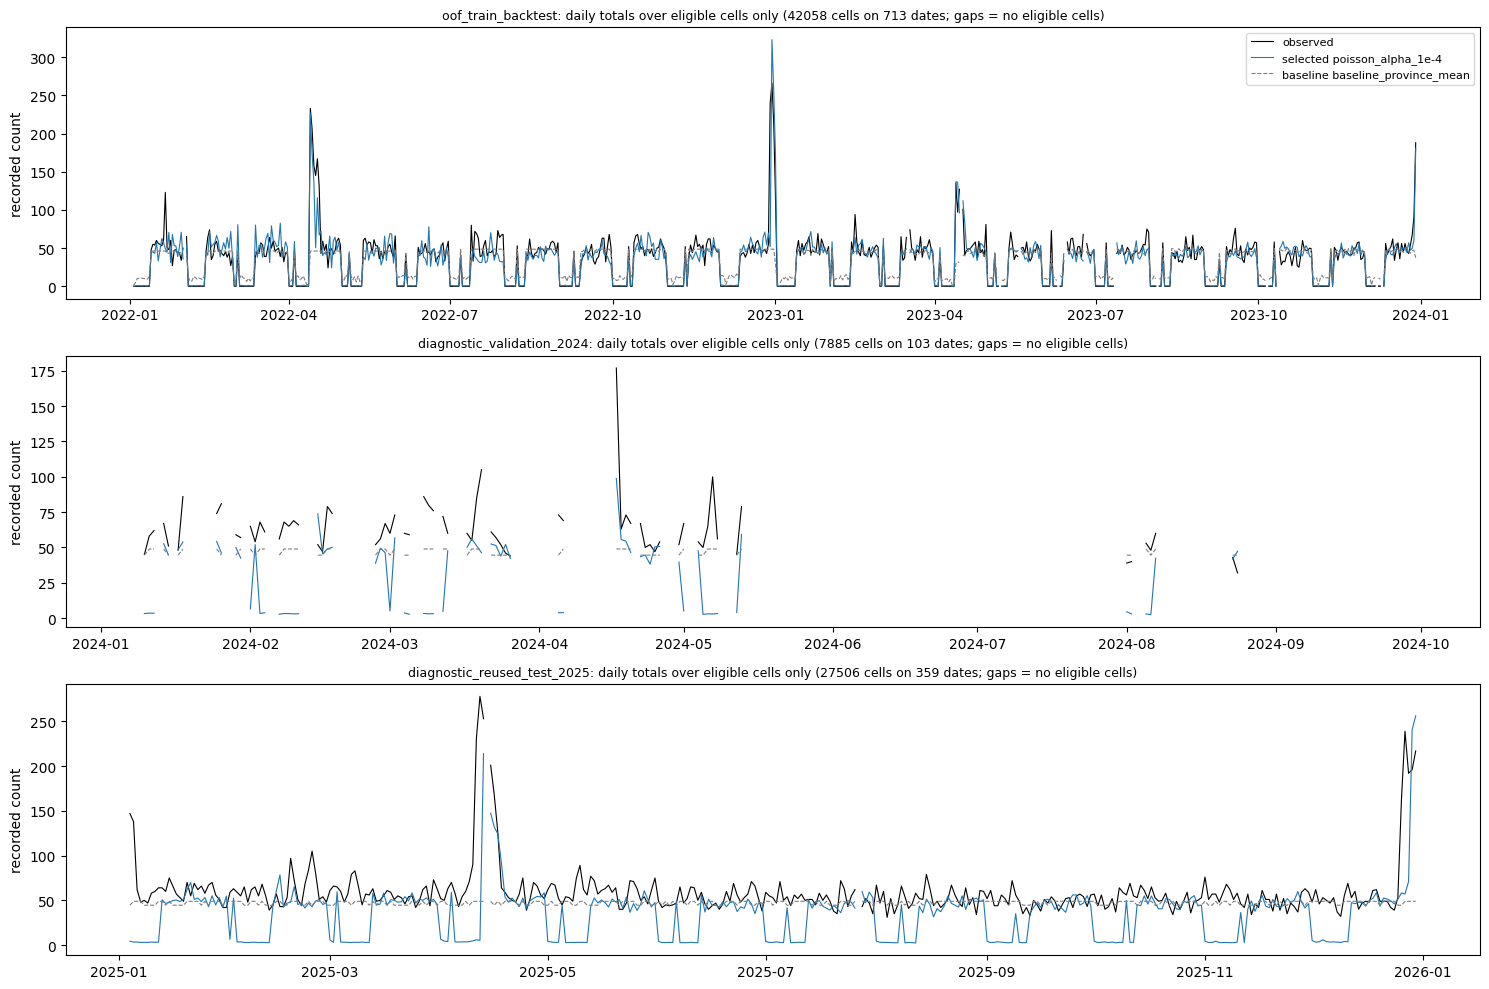

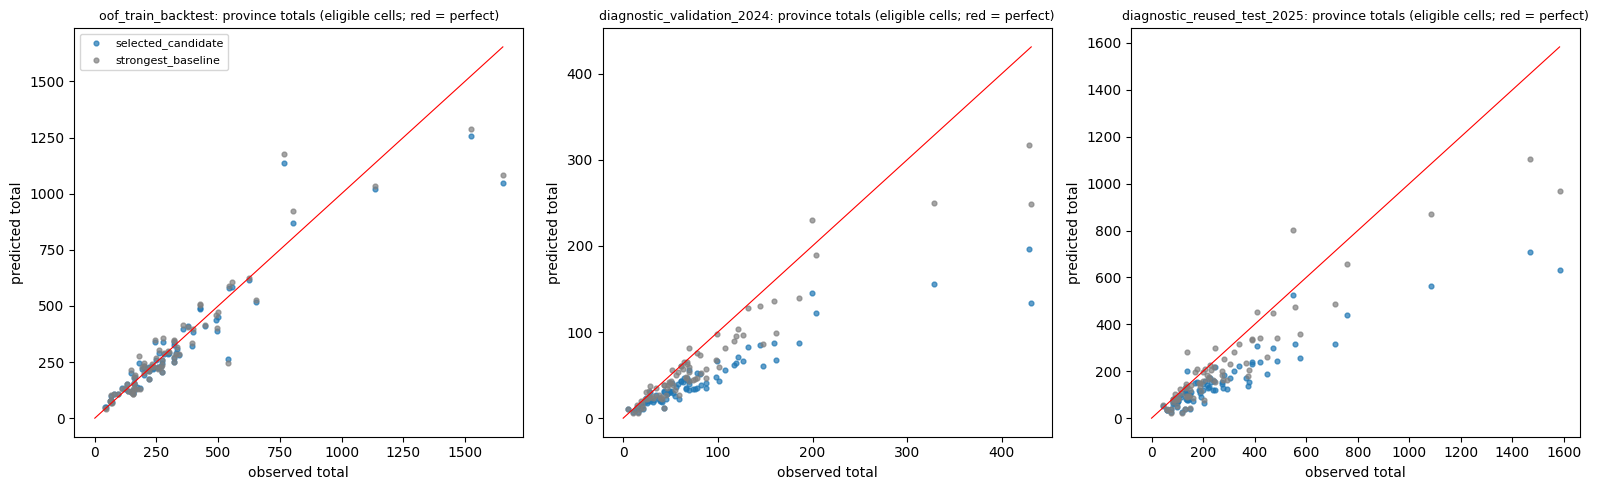

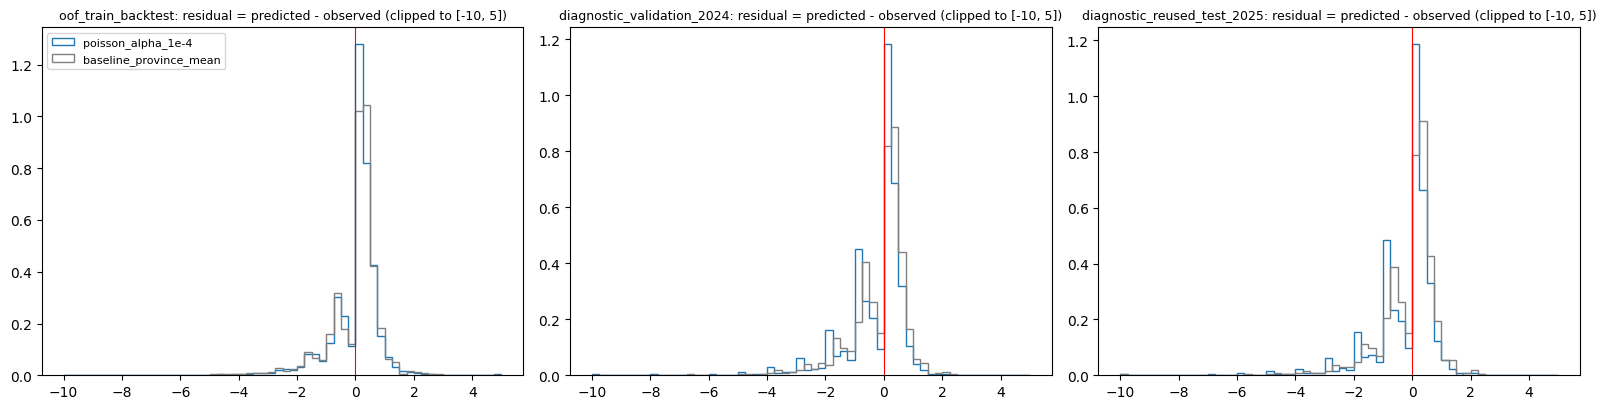

,evaluation_scope,role,spec_id,n_rows,mean,std,q05,q25,median,q75,q95,min,max,share_abs_error_ge_1,share_abs_error_ge_2
0,oof_train_backtest,selected_candidate,poisson_alpha_1e-4,42058,-0.028822,0.923820,-1.608682,-0.312640,0.124229,0.417552,0.922903,-13.074560,12.573331,0.137310,0.040397
1,oof_train_backtest,strongest_baseline,baseline_province_mean,42058,-0.016527,0.963134,-1.642523,-0.372477,0.215589,0.432941,0.944798,-15.961276,4.038724,0.140473,0.042846
2,diagnostic_validation_2024,selected_candidate,poisson_alpha_1e-4,7885,-0.355325,1.185328,-2.396503,-0.855440,0.027478,0.307995,0.730490,-19.701995,4.084538,0.172987,0.061636
3,diagnostic_validation_2024,strongest_baseline,baseline_province_mean,7885,-0.168581,1.032611,-2.045144,-0.586085,0.195202,0.402613,0.875000,-15.645669,3.077035,0.171718,0.056056
4,diagnostic_reused_test_2025,selected_candidate,poisson_alpha_1e-4,27506,-0.329022,1.217776,-2.334597,-0.851924,0.027016,0.318162,0.810638,-18.765588,8.807172,0.170108,0.061986
5,diagnostic_reused_test_2025,strongest_baseline,baseline_province_mean,27506,-0.159794,1.106082,-2.045144,-0.574780,0.211050,0.421245,0.924222,-18.058824,3.354331,0.168436,0.057078


In [8]:
DAILY = daily_totals(FRAME, ROLES)
DAILY.assign(target_date=DAILY['target_date'].dt.strftime('%Y-%m-%d')).to_csv(ERR / 'daily_totals.csv', index=False)
fig, axes = plt.subplots(len(ANALYSIS_SCOPES), 1, figsize=(15, 10))
for ax, scope in zip(axes, ANALYSIS_SCOPES):
    d = DAILY[DAILY['evaluation_scope'] == scope].set_index('target_date')
    full = d.reindex(pd.date_range(d.index.min(), d.index.max(), freq='D'))  # dates without eligible cells stay empty, not zero
    ax.plot(full.index, full['observed_total'], color='black', lw=0.8, label='observed')
    ax.plot(full.index, full['predicted_total__selected_candidate'], color='tab:blue', lw=0.8, label='selected ' + ROLES[0]['spec_id'])
    ax.plot(full.index, full['predicted_total__strongest_baseline'], color='tab:gray', lw=0.8, ls='--', label='baseline ' + ROLES[1]['spec_id'])
    ax.set_title('%s: daily totals over eligible cells only (%d cells on %d dates; gaps = no eligible cells)'
                 % (scope, int(d['n_eligible_cells'].sum()), len(d)), fontsize=9)
    ax.set_ylabel('recorded count')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(ERR / 'daily_observed_vs_predicted.png', dpi=100)
plt.show()

fig, axes = plt.subplots(1, len(ANALYSIS_SCOPES), figsize=(16, 5))
for ax, scope in zip(axes, ANALYSIS_SCOPES):
    s = SL_PROV[(SL_PROV['evaluation_scope'] == scope) & (SL_PROV['n_rows'] > 0)]
    for role, color in (('selected_candidate', 'tab:blue'), ('strongest_baseline', 'tab:gray')):
        r = s[s['role'] == role]
        ax.scatter(r['observed_total'].astype(float), r['predicted_total'].astype(float), s=12, alpha=0.7, color=color, label=role)
    hi = float(np.nanmax(pd.to_numeric(pd.concat([s['observed_total'], s['predicted_total']])).to_numpy())) if len(s) else 1.0
    ax.plot([0, hi], [0, hi], color='red', lw=0.8)
    ax.set_title(scope + ': province totals (eligible cells; red = perfect)', fontsize=9)
    ax.set_xlabel('observed total')
    ax.set_ylabel('predicted total')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(ERR / 'province_observed_vs_predicted.png', dpi=100)
plt.show()

RESID = residual_summary(FRAME, ROLES)
RESID.to_csv(ERR / 'residual_summary.csv', index=False)
fig, axes = plt.subplots(1, len(ANALYSIS_SCOPES), figsize=(16, 4.2))
edges = np.linspace(-10, 5, 61)
for ax, scope in zip(axes, ANALYSIS_SCOPES):
    sub = FRAME[FRAME['evaluation_scope'] == scope]
    for r, color in zip(ROLES, ('tab:blue', 'tab:gray')):
        ax.hist(np.clip(sub['pred__' + r['role']] - sub[TARGET], -10, 5), bins=edges, density=True, histtype='step', color=color, label=r['spec_id'])
    ax.axvline(0, color='red', lw=0.8)
    ax.set_title(scope + ': residual = predicted - observed (clipped to [-10, 5])', fontsize=9)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(ERR / 'residual_distributions.png', dpi=100)
plt.show()
RESID

## 5. Calibration-style bins (ขอบ bin จาก OOF เท่านั้น)

ขอบ bin = quantile แบบ `lower` ของ prediction OOF ของแต่ละโมเดล (เป้าหมาย 10 bin) ค่าซ้ำถูกรวมเป็นขอบเดียว จึงไม่มี bin กว้างศูนย์ และ predictor ค่าคงที่จะได้ bin เดียว `[v, v]` ขอบชุดเดียวกันถูกใช้กับปี 2024/2025 โดยไม่เปลี่ยน ค่าที่ต่ำกว่า/สูงกว่าช่วง OOF ตกใน bin แรก/สุดท้ายและนับแยก (`n_below_oof_range`, `n_above_oof_range`)

เป็นการเปรียบเทียบค่าเฉลี่ยทำนายกับค่าเฉลี่ยจริงเชิงพรรณนาเท่านั้น: **ไม่มีการ fit calibrator** และค่าทำนายเป็นจำนวนที่คาดหมาย ไม่ใช่ความน่าจะเป็น

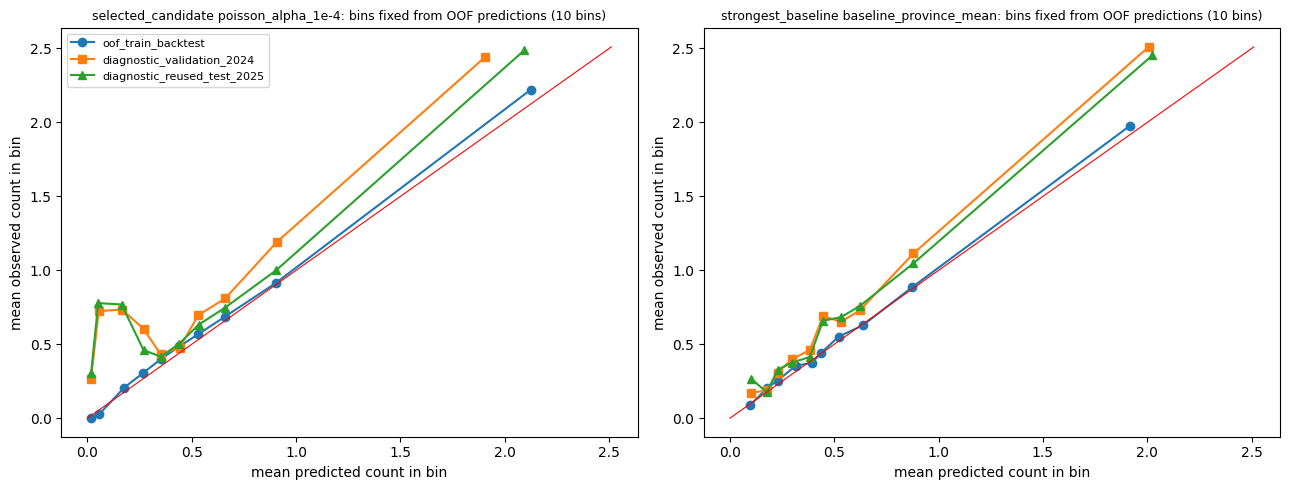

,evaluation_scope,role,bin,oof_edge_low,oof_edge_high,n_rows,mean_predicted,mean_observed,observed_over_predicted,n_below_oof_range,n_above_oof_range
0,oof_train_backtest,selected_candidate,0,0.003828,0.026756,4205,0.015983,0.000000,0.000000,0,0
1,oof_train_backtest,selected_candidate,1,0.026756,0.117202,4206,0.055374,0.025202,0.455122,0,0
2,oof_train_backtest,selected_candidate,2,0.117202,0.225043,4206,0.176165,0.206847,1.174168,0,0
3,oof_train_backtest,selected_candidate,3,0.225043,0.307806,4205,0.265900,0.304637,1.145686,0,0
4,oof_train_backtest,selected_candidate,4,0.307806,0.398808,4206,0.353399,0.401094,1.134960,0,0
5,oof_train_backtest,selected_candidate,5,0.398808,0.482000,4206,0.440607,0.485021,1.100804,0,0
6,oof_train_backtest,selected_candidate,6,0.482000,0.586584,4205,0.531081,0.568371,1.070216,0,0
7,oof_train_backtest,selected_candidate,7,0.586584,0.747722,4206,0.658727,0.686163,1.041650,0,0
8,oof_train_backtest,selected_candidate,8,0.747722,1.116110,4206,0.902210,0.913457,1.012466,0,0
9,oof_train_backtest,selected_candidate,9,1.116110,19.573331,4207,2.124681,2.221536,1.045586,0,0


In [9]:
OOF_FRAME = FRAME[FRAME['evaluation_scope'] == OOF_SCOPE]
EDGES = {r['role']: calibration_edges(OOF_FRAME['pred__' + r['role']], CALIBRATION_BINS) for r in ROLES}
CAL = calibration_table(FRAME, ROLES, EDGES)
oof_cal = CAL[CAL['evaluation_scope'] == OOF_SCOPE]
assert (oof_cal['n_rows'] > 0).all() and (oof_cal[['n_below_oof_range', 'n_above_oof_range']] == 0).all().all()
for scope in ANALYSIS_SCOPES:  # identical OOF edges in every scope
    for r in ROLES:
        c = CAL[(CAL['evaluation_scope'] == scope) & (CAL['role'] == r['role'])]
        assert c['oof_edge_low'].tolist() + c['oof_edge_high'].tolist()[-1:] == EDGES[r['role']]
CAL.to_csv(ERR / 'calibration_bins.csv', index=False)
write_json(ERR / 'calibration_edges.json', {'source_scope': OOF_SCOPE, 'method': "numpy quantile method='lower', duplicates collapsed",
                                            'n_bins_requested': CALIBRATION_BINS, 'edges': {r['spec_id']: EDGES[r['role']] for r in ROLES},
                                            'applied_unchanged_to': ANALYSIS_SCOPES[1:], 'calibrator_fitted': False, 'probability_claim': False})
fig, axes = plt.subplots(1, len(ROLES), figsize=(13, 5))
for ax, r in zip(axes, ROLES):
    for scope, mk in zip(ANALYSIS_SCOPES, ('o', 's', '^')):
        c = CAL[(CAL['evaluation_scope'] == scope) & (CAL['role'] == r['role']) & (CAL['n_rows'] > 0)]
        ax.plot(c['mean_predicted'].astype(float), c['mean_observed'].astype(float), marker=mk, label=scope)
    hi = float(np.nanmax(pd.to_numeric(pd.concat([CAL['mean_predicted'], CAL['mean_observed']])).to_numpy()))
    ax.plot([0, hi], [0, hi], color='red', lw=0.8)
    ax.set_title('%s %s: bins fixed from OOF predictions (%d bins)' % (r['role'], r['spec_id'], len(EDGES[r['role']]) - 1), fontsize=9)
    ax.set_xlabel('mean predicted count in bin')
    ax.set_ylabel('mean observed count in bin')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(ERR / 'calibration_bins.png', dpi=100)
plt.show()
CAL[['evaluation_scope', 'role', 'bin', 'oof_edge_low', 'oof_edge_high', 'n_rows', 'mean_predicted', 'mean_observed', 'observed_over_predicted',
     'n_below_oof_range', 'n_above_oof_range']]

## 6. การเปลี่ยน cohort หลัง cleaning: วันที่ 1–12 เทียบ 13–31 (คำนวณใหม่จาก panel)

คำนวณจาก panel ที่ตรวจ hash แล้ว: จำนวน province-day ทั้งหมด (ตัวหาร), จำนวนที่ eligible, ผลรวม/ค่าเฉลี่ยเหตุ และสัดส่วนวันที่มีเหตุ แยก Train / 2024 / 2025 และวันที่ 1–12 กับ 13–31 พร้อม error ของ selected candidate และ baseline ในกลุ่มเดียวกัน (Train ใช้แถว OOF ปี 2022–2023 เท่านั้น ปีหลังใช้ prediction ของ 07)

ตรวจด้วยว่าแถว eligible ที่มีเหตุในวันที่ 1–12 มีเลขวันเท่ากับเลขเดือนหรือไม่ (วันที่ที่อ่านแบบ D/M และ M/D ได้ค่าเดียวกันจึงไม่กำกวม) ตามนโยบายใน `config/data_pipeline.json` วันที่ slash ที่กำกวมถูกกักกันและวันที่ผู้สมัครทั้งสองถูกธง `possibly_undercounted` (ไม่ eligible) ขณะที่ข้อมูลปีหลังเป็นวันที่แบบ Excel — **เป็นหลักฐานของ cohort/selection bias ไม่ใช่กลไกเชิงสาเหตุของอุบัติเหตุ** และไม่ใช้เปลี่ยน cleaning, mask, feature หรือตัวเลือกที่ล็อก

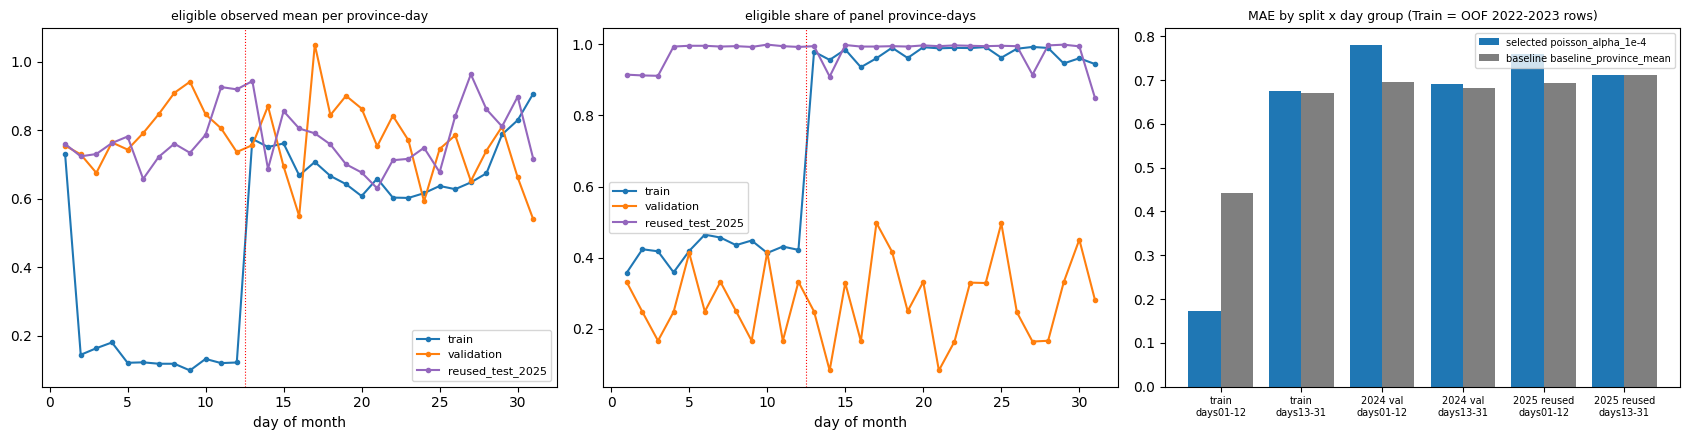

,split,day_group,panel_rows,eligible_rows,eligible_share_of_panel,eligible_observed_total,eligible_observed_mean,eligible_positive_share,error_scope,error_rows,...,selected_candidate__predicted_mean,selected_candidate__mae,selected_candidate__rmse,selected_candidate__bias,selected_candidate__mean_poisson_deviance,strongest_baseline__predicted_mean,strongest_baseline__mae,strongest_baseline__rmse,strongest_baseline__bias,strongest_baseline__mean_poisson_deviance
0,train,days01-12,33264,14001,0.420905,2407.0,0.171916,0.083423,oof_train_backtest,9125,...,0.175002,0.173306,0.576802,0.008974,0.287746,0.404483,0.441573,0.735967,0.238456,0.890281
1,train,days13-31,51051,49756,0.974633,34151.0,0.686369,0.398505,oof_train_backtest,32933,...,0.657058,0.675498,0.999396,-0.039295,1.117057,0.609176,0.669673,1.017312,-0.087177,1.174068
2,validation,days01-12,11088,3067,0.276605,2433.0,0.793283,0.437561,diagnostic_validation_2024,3067,...,0.123261,0.779140,1.501401,-0.670022,3.787274,0.619596,0.694767,1.073637,-0.173687,1.140095
3,validation,days13-31,17094,4818,0.281853,3735.0,0.775218,0.432960,diagnostic_validation_2024,4818,...,0.620221,0.690801,1.034917,-0.154997,1.140529,0.609887,0.682590,1.028490,-0.165331,1.162059
4,reused_test_2025,days01-12,11088,10801,0.974116,8346.0,0.772706,0.430886,diagnostic_reused_test_2025,10801,...,0.088055,0.760125,1.480026,-0.684651,3.930119,0.616078,0.693554,1.091417,-0.156628,1.207910
5,reused_test_2025,days13-31,17017,16705,0.981665,13016.0,0.779168,0.426818,diagnostic_reused_test_2025,16705,...,0.680085,0.711077,1.097170,-0.099083,1.171328,0.617327,0.711901,1.134151,-0.161841,1.269547


,split,eligible_rows_day01_12,day_equals_month_rows,day_equals_month_share,positive_rows_day01_12,positive_day_equals_month_rows,positive_day_equals_month_share,positive_day_not_equal_month_rows
0,train,14001,2711,0.193629,1168,1168,1.000000,0
1,validation,3067,152,0.049560,1342,67,0.049925,1275
2,reused_test_2025,10801,843,0.078048,4654,350,0.075204,4304


In [10]:
REGIME_SPLITS = [s['name'] for s in SPLITS]
REGIME = cleaning_regime_table(panel, FRAME, ROLES, FLOOR, REGIME_SPLITS)
DAY_EQ = day_equals_month_check(panel, REGIME_SPLITS)
DOM = day_of_month_profile(panel, REGIME_SPLITS)
sup06 = pd.read_csv(REP / 'support_by_split_month.csv')  # bytes verified against the 06 manifest
for sp in REGIME_SPLITS:  # recomputed counts agree with the 06 support table
    s06 = sup06[sup06['split'] == sp]
    assert int(REGIME.loc[REGIME['split'] == sp, 'eligible_rows'].sum()) == int(s06['eligible_rows'].sum()) == int(DOM.loc[DOM['split'] == sp, 'eligible_rows'].sum())
    assert int(REGIME.loc[REGIME['split'] == sp, 'panel_rows'].sum()) == int(s06['panel_rows'].sum())
    assert round(float(REGIME.loc[REGIME['split'] == sp, 'eligible_observed_total'].fillna(0).sum())) == int(s06['eligible_target_sum'].sum())
REGIME.to_csv(ERR / 'cleaning_regime_day_group.csv', index=False)
DAY_EQ.to_csv(ERR / 'day_equals_month_check.csv', index=False)
DOM.to_csv(ERR / 'day_of_month_profile.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for sp, color in zip(REGIME_SPLITS, ('tab:blue', 'tab:orange', 'tab:purple')):
    d = DOM[DOM['split'] == sp]
    axes[0].plot(d['day_of_month'], d['eligible_observed_mean'].astype(float), marker='.', color=color, label=sp)
    axes[1].plot(d['day_of_month'], d['eligible_share_of_panel'].astype(float), marker='.', color=color, label=sp)
for ax, t in zip(axes[:2], ('eligible observed mean per province-day', 'eligible share of panel province-days')):
    ax.axvline(12.5, color='red', lw=0.8, ls=':')
    ax.set_xlabel('day of month')
    ax.set_title(t, fontsize=9)
    ax.legend(fontsize=8)
lab = [{'validation': '2024 val', 'reused_test_2025': '2025 reused'}.get(sp, sp) + chr(10) + g for sp, g in zip(REGIME['split'], REGIME['day_group'])]  # display names only
xs = np.arange(len(REGIME))
axes[2].bar(xs - 0.2, REGIME['selected_candidate__mae'].astype(float), width=0.4, color='tab:blue', label='selected ' + ROLES[0]['spec_id'])
axes[2].bar(xs + 0.2, REGIME['strongest_baseline__mae'].astype(float), width=0.4, color='tab:gray', label='baseline ' + ROLES[1]['spec_id'])
axes[2].set_xticks(xs)
axes[2].set_xticklabels(lab, fontsize=7)
axes[2].set_title('MAE by split x day group (Train = OOF 2022-2023 rows)', fontsize=9)
axes[2].legend(fontsize=7)
fig.tight_layout()
fig.savefig(ERR / 'cleaning_regime_shift.png', dpi=100)
plt.show()
display(REGIME)
DAY_EQ

## 7. Model card และสรุปการตัดสินใจ (สร้างจากผลจริงในเซลล์ด้านบน)

ตอบว่าตัวดีที่สุดของแต่ละตระกูลคือ configuration ใด ตัวไหนถูกเลือกจาก OOF ผล gate/bootstrap/fold เทียบ baseline ข้อแลกเปลี่ยน MAE/RMSE/ความตีความได้/เวลา และการกลับอันดับในปีหลังกับการเปลี่ยน cohort อย่างเด่นชัด recommended reference ตาม protocol OOF ยังคงที่ แต่ **ไม่ใช่การอนุมัติใช้งาน**: ข้อเสนอเชิงปฏิบัติคือระงับการนำไปใช้และแก้ blocker ของข้อมูลก่อนพยากรณ์ล่วงหน้า ไฟล์ถูกเขียนในเซลล์สุดท้ายหลังตรวจ lock และไฟล์ upstream อีกครั้ง

In [11]:
OM = OOF_M_FILE.set_index('spec_id')  # values re-derived above (OOF_RECHECK)
DM = DIAG_M.set_index(['evaluation_scope', 'spec_id'])
FIT_FULL = pd.read_csv(REP / 'fit_log_full_train.csv').set_index('spec_id')  # 06 log (bytes verified; timing nondeterministic)
RT07 = pd.read_csv(DIAG / 'runtime_by_spec.csv').set_index('spec_id')  # 07 runtime (bytes verified via the 07 manifest)
GE = GATE_EVIDENCE.set_index('spec_id')
MKEYS = ['n_rows', 'mean_poisson_deviance', 'mae', 'rmse', 'bias', 'observed_total', 'predicted_total']
ALL_CFG_LOWEST = {m: min((s['id'] for s in XCFG['candidates']), key=lambda i: (float(OM.loc[i, m]), i)) for m in ('mean_poisson_deviance', 'mae', 'rmse')}  # report only across all candidate configs; selection stays per primary metric
TRAIN_ELIG_DATES = cohort(panel, TRAIN_SPLIT, XCFG['cohort']['eligibility_column'])['target_date'].agg(['min', 'max']).dt.strftime('%Y-%m-%d').tolist()  # actual eligible Train dates
oof_block = lambda sid: {k: to_jsonable(OM.loc[sid, k]) for k in MKEYS + ['wape']}
later_block = lambda sid: {sc: {k: to_jsonable(DM.loc[(sc, sid), k]) for k in MKEYS} for sc in LATER_SCOPES_08}
runtime_block = lambda sid: {'fit_seconds_full_train_06': float(FIT_FULL.loc[sid, 'fit_seconds']),
                             'predict_microseconds_per_cell_07': float(RT07.loc[sid, 'predict_microseconds_per_cell'])}
CANDIDATES = []
for fam in FAMILY_ORDER:
    sid = CHOICE['best_per_family'][fam]
    CANDIDATES.append({'family': fam, 'spec_id': sid, 'is_selected_candidate': sid == CHOICE['selected_candidate'], 'params': SPEC[sid]['params'],
                       'encoding': XCFG['encoding'][fam], 'other_configs_tried': [s['id'] for s in XCFG['candidates'] if s['family'] == fam and s['id'] != sid],
                       'oof': oof_block(sid), 'later_years': later_block(sid),
                       'oof_bootstrap_vs_strongest_baseline': {k: to_jsonable(GE.loc[sid, k]) for k in ('point_estimate', 'ci_low', 'ci_high', 'ci_level', 'replicates', 'block_days', 'seed')},
                       'runtime_nondeterministic': runtime_block(sid)})
fb = {c['spec_id']: c['oof'] for c in CANDIDATES}
TRADEOFFS = {k: min(fb, key=lambda i: (fb[i][m], i)) for k, m in (('lowest_oof_deviance', 'mean_poisson_deviance'), ('lowest_oof_mae', 'mae'), ('lowest_oof_rmse', 'rmse'))}
OPREC = operational_recommendation(XCFG['production_enabled'], DATA_REPORT['final_model_readiness'], REVERSAL, bool(CHOICE['stable_gain']))
rv = REVERSAL.set_index('evaluation_scope')
rg = REGIME.set_index(['split', 'day_group'])
de = DAY_EQ.set_index('split')
OB = SL_CAL[SL_CAL['slice'] == 'outcome_bin']
NEXT_DATA_WORK = [
    'ยืนยัน convention ของวันที่แบบ slash ต่อไฟล์กับผู้เผยแพร่/เอกสารต้นทาง แล้วกู้คืนแถวที่ถูกกักกันอย่างมีหลักฐาน (ลด selection bias ช่วงวันที่ 1–12 ของ Train)',
    'ตรวจเวลาที่ข้อมูลรายงานพร้อมใช้จริง (reporting availability) เพื่อยืนยันว่า feature/label สอดคล้องกับเวลาออกพยากรณ์ 18:00 ของวันก่อนหน้า',
    'ตรวจการจับคู่จังหวัด/พื้นที่ และกำหนดหน่วยสายทางจริงก่อนทำ route model',
    'กำหนดช่วงทดสอบล่วงหน้า (prospective) ที่ยังไม่เคยเห็น แล้วรัน 06–08 ใหม่ภายใต้ protocol เวอร์ชันใหม่ ห้าม tune บนปี 2024/2025',
] + ['blocker จาก data foundation: ' + str(b) for b in (DATA_REPORT.get('unresolved_blockers') or [])]
LIMITATIONS = [
    'คะแนนทั้งหมดเป็นของเซลล์ province-day ที่ training_eligible (ตัวกรองคุณภาพที่รู้หลังเห็นปัญหา) จึงมี selection bias ไม่ใช่ทั้งปี ทั้งประเทศ หรือรายสายทาง',
    'ปี 2024 ไม่มีเซลล์ eligible ในเดือน ต.ค.–ธ.ค.; ปี 2025 เคยถูกดูแล้ว จึงไม่มี test อิสระ; ไม่ใช้ label ปี 2026',
    'feature มีเพียงจังหวัดและปฏิทิน (ไม่มี lag สภาพอากาศ วันหยุด/เทศกาล หรือการจราจร) จึงไม่อ้างผลของปัจจัยเหล่านั้น',
    'ค่าทำนายเป็นจำนวนเหตุที่บันทึกต่อ province-day ไม่ใช่ความน่าจะเป็นรายบุคคล และไม่มีการ calibrate',
    'bootstrap เป็นการสำรวจ ไม่ปรับสำหรับการเลือกหลายโมเดล; Random Forest แบบขนานอาจต่างกันระดับ 1e-15 ระหว่างการรัน',
]
SUMMARY = {
    'producer': PRODUCER_08, 'format': SUMMARY_FORMAT_08, 'status': 'ok', 'experiment_id': XCFG['experiment_id'],
    'research_mode': XCFG['research_mode'], 'production_enabled': False, 'final_model_readiness': 'BLOCKED',
    'data_foundation_final_model_readiness': DATA_REPORT['final_model_readiness'],
    'answers': {'three_candidate_family_bests': {c['family']: c['spec_id'] for c in CANDIDATES},
                'selected_candidate_from_oof': CHOICE['selected_candidate'], 'strongest_baseline_from_oof': CHOICE['best_baseline'],
                'locked_oof_recommended_reference': CHOICE['recommended_reference'], 'locked_oof_recommended_reference_type': CHOICE['recommended_reference_type'],
                'oof_gate_stable_gain': bool(CHOICE['stable_gain']),
                'locked_reference_meaning': 'reference within the locked OOF comparison protocol only; NOT a deployment approval',
                'later_year_any_family_best_beats_strongest_baseline': {sc: (None if pd.isna(rv.loc[sc, 'n_family_bests_beating_baseline']) else bool(rv.loc[sc, 'n_family_bests_beating_baseline'] > 0)) for sc in LATER_SCOPES_08},
                'deployment': OPREC['deployment']},
    'frozen_choice': CHOICE, 'decision_sha256': LOCK['decision_sha256'], 'choice_sha256': LOCK['choice_sha256'],
    'selection_lock_file_sha256': LOCK_FILE_SHA_BEFORE,
    'candidates': CANDIDATES,
    'strongest_baseline': {'spec_id': CHOICE['best_baseline'], 'kind': SPEC[CHOICE['best_baseline']].get('kind'), 'params': SPEC[CHOICE['best_baseline']]['params'],
                           'oof': oof_block(CHOICE['best_baseline']), 'later_years': later_block(CHOICE['best_baseline']),
                           'runtime_nondeterministic': runtime_block(CHOICE['best_baseline'])},
    'zero_baseline_diagnostic': {'spec_id': 'baseline_zero', 'oof': oof_block('baseline_zero'), 'later_years': later_block('baseline_zero'),
                                 'note': 'Poisson deviance undefined (null) for an all-zero predictor'},
    'oof_gate': {'criteria': DEC['gate']['criteria'], 'per_fold_deviance': DEC['gate']['per_fold_deviance'], 'reasoning': DEC['gate']['reasoning'],
                 'bootstrap_params': XCFG['bootstrap'], 'bootstrap_note': 'paired moving-block bootstrap over calendar days; exploratory, not adjusted for model selection'},
    'oof_tradeoffs_among_family_bests': TRADEOFFS, 'oof_lowest_among_all_candidate_configs_report_only': ALL_CFG_LOWEST,
    'later_year_reversal': records(REVERSAL),
    'data_shift': {'cleaning_regime_day_group': records(REGIME), 'day_equals_month_check': records(DAY_EQ),
                   'interpretation': 'cohort/selection-bias evidence consistent with ambiguous slash-date quarantine in Train versus Excel dates later; not a causal crash mechanism'},
    'error_analysis_files': 'reports/models/error_analysis/',
    'scope': {'unit': DCFG['forecast']['target_unit'], 'unit_status': DCFG['forecast']['unit_status'],
              'issue_time': '%02d:00 local (%s), %d day(s) before the target day' % (DCFG['forecast']['issue_hour_local'], DCFG['timezone_assumption'], DCFG['forecast']['issue_days_before_target']),
              'horizon': 'one province-day ahead; retrospective research, not a verified as-of forecast', 'features': FEATURES,
              'train_split_configured_range': [SPLITS[0]['start'], SPLITS[0]['end']], 'train_eligible_actual_date_range': TRAIN_ELIG_DATES, 'n_train_eligible_rows': int(EXP_MAN['n_train_eligible_rows']),
              'oof_folds': XCFG['folds'], 'support': records(SUPPORT)},
    'operational_recommendation': OPREC, 'next_data_work': NEXT_DATA_WORK, 'known_limitations': LIMITATIONS,
    'unsupported_claims': ['weather effects', 'festival/holiday effects', 'traffic effects', 'route-level or hourly accuracy', 'personal crash probability',
                           'full-year or whole-country accuracy'],
    'deferred': ['route-level model', 'API', 'UI / dashboard', 'weather/festival/traffic features'],
    'permutation_sensitivity': PERMUTATION_SENSITIVITY_08,
}
json.loads(json.dumps(to_jsonable(SUMMARY), allow_nan=False))  # strict finite JSON before anything is written

f4 = lambda x: 'null' if x is None or pd.isna(x) else '%.4f' % float(x)
selc = next(c for c in CANDIDATES if c['is_selected_candidate'])
rev_scopes = [sc for sc in LATER_SCOPES_08 if pd.notna(rv.loc[sc, 'no_family_best_beats_baseline']) and bool(rv.loc[sc, 'no_family_best_beats_baseline'])]
cand_tbl = pd.DataFrame([{'family': c['family'], 'spec_id': c['spec_id'], 'selected': c['is_selected_candidate'], 'OOF deviance': c['oof']['mean_poisson_deviance'],
                          'OOF MAE': c['oof']['mae'], 'OOF RMSE': c['oof']['rmse'], 'bootstrap CI low': c['oof_bootstrap_vs_strongest_baseline']['ci_low'],
                          'bootstrap CI high': c['oof_bootstrap_vs_strongest_baseline']['ci_high'],
                          'fit s (06)': c['runtime_nondeterministic']['fit_seconds_full_train_06'],
                          'predict us/cell (07)': c['runtime_nondeterministic']['predict_microseconds_per_cell_07']} for c in CANDIDATES]
                        + [{'family': 'baseline', 'spec_id': CHOICE['best_baseline'], 'selected': False, 'OOF deviance': OM.loc[CHOICE['best_baseline'], 'mean_poisson_deviance'],
                            'OOF MAE': OM.loc[CHOICE['best_baseline'], 'mae'], 'OOF RMSE': OM.loc[CHOICE['best_baseline'], 'rmse'], 'bootstrap CI low': None,
                            'bootstrap CI high': None, 'fit s (06)': runtime_block(CHOICE['best_baseline'])['fit_seconds_full_train_06'],
                            'predict us/cell (07)': runtime_block(CHOICE['best_baseline'])['predict_microseconds_per_cell_07']}])
later_tbl = pd.DataFrame([{'scope': sc, 'n': int(DM.loc[(sc, sid), 'n_rows']), 'spec_id': sid + (' (selected)' if sid == CHOICE['selected_candidate'] else ''),
                           'deviance': DM.loc[(sc, sid), 'mean_poisson_deviance'], 'MAE': DM.loc[(sc, sid), 'mae'], 'RMSE': DM.loc[(sc, sid), 'rmse'],
                           'bias': DM.loc[(sc, sid), 'bias']} for sc in LATER_SCOPES_08 for sid in FOCUS_IDS[:-1]])
crit_tbl = pd.DataFrame([{'criterion': k, 'value': v['value'], 'rule': v['rule'], 'passed': v['passed']} for k, v in DEC['gate']['criteria'].items()])
fold_tbl = pd.DataFrame([{'fold': int(k), 'selected deviance': v['candidate'], 'baseline deviance': v['baseline']} for k, v in DEC['gate']['per_fold_deviance'].items()])
reg_tbl = REGIME.rename(columns={'selected_candidate__mae': 'selected MAE', 'strongest_baseline__mae': 'baseline MAE'})
L = ['# Model card — RoadAware แบบจำลองวิจัยย้อนหลังระดับจังหวัด–วัน (' + XCFG['experiment_id'] + ')', '',
     '> สร้างโดย Notebook 08 จากผลจริงที่ตรวจ hash แล้ว | `production_enabled = false` | `final_model_readiness = BLOCKED` | โหมด `' + XCFG['research_mode'] + '`', '',
     '## ⚠️ ข้อค้นพบสำคัญที่สุด: ผลในปีหลังกลับอันดับ และข้อมูลเปลี่ยน regime', '',
     '- Poisson ถูกเลือกและผ่าน gate ที่ล็อกไว้บน OOF 2022–2023 แต่บนเซลล์ eligible ปีหลัง strongest baseline (`%s`) มี Poisson deviance %s (2024) และ %s (2025) เทียบกับ selected candidate %s และ %s'
     % (CHOICE['best_baseline'], f4(rv.loc['diagnostic_validation_2024', 'strongest_baseline_deviance']), f4(rv.loc['diagnostic_reused_test_2025', 'strongest_baseline_deviance']),
        f4(rv.loc['diagnostic_validation_2024', 'selected_candidate_deviance']), f4(rv.loc['diagnostic_reused_test_2025', 'selected_candidate_deviance'])),
     '- จำนวนตัวดีที่สุดของตระกูล (จาก 3) ที่ชนะ baseline ใน primary metric: ' + ', '.join('%s = %s' % (sc, rv.loc[sc, 'n_family_bests_beating_baseline']) for sc in LATER_SCOPES_08)
     + ('; **ทั้งสาม candidate แพ้ baseline ค่าเฉลี่ยรายจังหวัด** ใน ' + ', '.join(rev_scopes) if rev_scopes else ''),
     '- cohort หลัง cleaning ต่างกัน: ใน Train วันที่ 1–12 มีค่าเฉลี่ย %s เหตุต่อ province-day (eligible %s ของ panel) เทียบวันที่ 13–31 = %s ขณะที่ปี 2024 เป็น %s / %s และปี 2025 เป็น %s / %s'
     % (f4(rg.loc[('train', 'days01-12'), 'eligible_observed_mean']), f4(rg.loc[('train', 'days01-12'), 'eligible_share_of_panel']),
        f4(rg.loc[('train', 'days13-31'), 'eligible_observed_mean']), f4(rg.loc[('validation', 'days01-12'), 'eligible_observed_mean']),
        f4(rg.loc[('validation', 'days13-31'), 'eligible_observed_mean']), f4(rg.loc[('reused_test_2025', 'days01-12'), 'eligible_observed_mean']),
        f4(rg.loc[('reused_test_2025', 'days13-31'), 'eligible_observed_mean'])),
     '- แถว eligible ที่มีเหตุในวันที่ 1–12 ของ Train: %d แถว ในนี้ %d แถวมีเลขวันเท่ากับเลขเดือน (สัดส่วน %s) สอดคล้องกับการกักกันวันที่ slash ที่กำกวม ต่างจากปีหลังที่เป็นวันที่แบบ Excel — เป็นหลักฐาน cohort/selection bias ไม่ใช่สาเหตุของอุบัติเหตุ'
     % (de.loc['train', 'positive_rows_day01_12'], de.loc['train', 'positive_day_equals_month_rows'], f4(de.loc['train', 'positive_day_equals_month_share'])),
     '- ดังนั้นชัยชนะใน OOF อาจไม่ข้าม regime ได้ การเลือกจาก OOF ยังคงตาม protocol แต่ผลปีหลังเป็นข้อจำกัดหลัก', '',
     '## คำตอบการเลือกโมเดล (ล็อกจาก OOF ก่อนให้คะแนนปีหลัง)', '',
     '- ตัวดีที่สุดของสามตระกูล: ' + '; '.join('%s = `%s` %s' % (c['family'], c['spec_id'], json.dumps(c['params'], ensure_ascii=False)) for c in CANDIDATES),
     '- **selected candidate:** `%s` | **strongest baseline:** `%s` | **recommended reference ตาม protocol OOF:** `%s` (%s, stable_gain = %s)'
     % (CHOICE['selected_candidate'], CHOICE['best_baseline'], CHOICE['recommended_reference'], CHOICE['recommended_reference_type'], CHOICE['stable_gain']),
     '- recommended reference นี้เป็นผลของกติกาเปรียบเทียบ OOF ที่ล็อกไว้เท่านั้น **ไม่ใช่การอนุมัติให้ใช้งานจริง**', '',
     md_table(cand_tbl, list(cand_tbl.columns)), '',
     '- ข้อแลกเปลี่ยนบน OOF ในสาม configuration ที่ล็อกจากแต่ละตระกูลตาม primary metric: deviance ต่ำสุด = `%s`, MAE ต่ำสุด = `%s`, RMSE ต่ำสุด = `%s`; ถ้าดูทุก candidate configuration ที่ทดลอง (รายงานเท่านั้น ไม่ใช่เกณฑ์เลือก) MAE ต่ำสุด = `%s` และ RMSE ต่ำสุด = `%s` — Poisson ตีความได้ง่ายกว่า (log-linear one-hot) ส่วน Random Forest/HGB จับความไม่เป็นเส้นตรงได้ เวลา fit/predict เป็นค่าที่วัดจริงแต่ไม่ deterministic'
     % (TRADEOFFS['lowest_oof_deviance'], TRADEOFFS['lowest_oof_mae'], TRADEOFFS['lowest_oof_rmse'], ALL_CFG_LOWEST['mae'], ALL_CFG_LOWEST['rmse']),
     '- bootstrap: paired 7-day calendar block, %d รอบ, seed %d; ผลต่าง = deviance ของ candidate − baseline (ติดลบ = candidate ดีกว่า) เป็นการสำรวจ ไม่ปรับสำหรับการเลือกหลายตัว' % (XCFG['bootstrap']['replicates'], XCFG['bootstrap']['seed']), '',
     '### Gate ที่ล็อกไว้ (OOF)', '', md_table(crit_tbl, list(crit_tbl.columns)), '', md_table(fold_tbl, list(fold_tbl.columns)), '',
     '## ผลปีหลัง (เซลล์ eligible เท่านั้น; การวินิจฉัย ไม่ใช่การเลือกใหม่)', '', md_table(later_tbl, list(later_tbl.columns)), '',
     '## Error analysis โดยสรุป', '',
     'ช่วงจำนวนจริง (outcome bins เป็นการวินิจฉัย ไม่ใช่ input):', '',
     md_table(OB, ['evaluation_scope', 'level', 'role', 'n_rows', 'observed_total', 'predicted_total', 'mae', 'rmse', 'bias']), '',
     'การเปลี่ยน cohort แยกวันที่ 1–12 / 13–31 (คำนวณจาก panel; error ของ Train มาจากแถว OOF 2022–2023):', '',
     md_table(reg_tbl, ['split', 'day_group', 'panel_rows', 'eligible_rows', 'eligible_share_of_panel', 'eligible_observed_mean', 'eligible_positive_share', 'error_rows', 'selected MAE', 'baseline MAE']), '',
     'ตารางรายเดือน/จังหวัด/วันในสัปดาห์, กลุ่มที่ทำนายเกิน/ขาดมากที่สุด, calibration-style bins และกราฟอยู่ที่ `reports/models/error_analysis/`', '',
     '## ขอบเขต ข้อมูล และ feature', '',
     '- หน่วย: `%s` (%s); ออกพยากรณ์ %s; horizon หนึ่ง province-day ล่วงหน้า (งานวิจัยย้อนหลัง ไม่ใช่ as-of forecast ที่ยืนยันแล้ว)' % (SUMMARY['scope']['unit'], SUMMARY['scope']['unit_status'], SUMMARY['scope']['issue_time']),
     '- feature: ' + ', '.join('`%s`' % x for x in FEATURES) + ' (จังหวัด + ปฏิทินเท่านั้น); encoding ตาม config ที่ล็อก',
     '- Train: ช่วง split ตาม config %s–%s; วันที่จริงของเซลล์ eligible %s–%s จำนวน %d province-day; OOF 4 fold ปี 2022–2023 %d แถว; ปี 2024 %d แถว; ปี 2025 %d แถว'
     % (SPLITS[0]['start'], SPLITS[0]['end'], TRAIN_ELIG_DATES[0], TRAIN_ELIG_DATES[1], int(EXP_MAN['n_train_eligible_rows']), int(SUPPORT['rows'].iloc[0]), int(SUPPORT['rows'].iloc[1]), int(SUPPORT['rows'].iloc[2])), '',
     '## ข้อเสนอเชิงปฏิบัติ', '',
     '- **ระงับการนำไปใช้งาน (deployment = %s)** และ prospective_forecast_allowed = %s เหตุผล:' % (OPREC['deployment'], OPREC['prospective_forecast_allowed'])] + ['  - ' + r for r in OPREC['reasons']] + [
     '- งานข้อมูลถัดไป (ก่อนพยากรณ์ล่วงหน้าใดๆ):'] + ['  - ' + x for x in NEXT_DATA_WORK] + ['',
     '## ข้อจำกัดที่ทราบ', ''] + ['- ' + x for x in LIMITATIONS] + ['',
     '- ไม่รองรับการอ้างเรื่อง: ' + ', '.join(SUMMARY['unsupported_claims']),
     '- เลื่อนไปขั้นถัดไป: ' + ', '.join(SUMMARY['deferred']),
     '- grouped permutation sensitivity (ข้อ 8 ของงาน): ไม่ได้ทำ — ' + PERMUTATION_SENSITIVITY_08['reason'], '',
     '## ที่มา', '',
     '- decision_sha256 `%s`; choice_sha256 `%s`; selection_lock.json sha256 `%s`' % (LOCK['decision_sha256'], LOCK['choice_sha256'], LOCK_FILE_SHA_BEFORE),
     '- OOF predictions sha256 `%s`; diagnostic predictions sha256 `%s`' % (ART_MAN['oof_predictions_sha256'], NSC['predictions']['sha256']),
     '- package versions: ' + json.dumps(package_versions(), ensure_ascii=False), '']
CARD = NL.join(L)
display(Markdown(CARD))

# Model card — RoadAware แบบจำลองวิจัยย้อนหลังระดับจังหวัด–วัน (roadaware_model_experiment_v1)

> สร้างโดย Notebook 08 จากผลจริงที่ตรวจ hash แล้ว | `production_enabled = false` | `final_model_readiness = BLOCKED` | โหมด `retrospective_conditional_research`

## ⚠️ ข้อค้นพบสำคัญที่สุด: ผลในปีหลังกลับอันดับ และข้อมูลเปลี่ยน regime

- Poisson ถูกเลือกและผ่าน gate ที่ล็อกไว้บน OOF 2022–2023 แต่บนเซลล์ eligible ปีหลัง strongest baseline (`baseline_province_mean`) มี Poisson deviance 1.1535 (2024) และ 1.2453 (2025) เทียบกับ selected candidate 2.1700 และ 2.2546
- จำนวนตัวดีที่สุดของตระกูล (จาก 3) ที่ชนะ baseline ใน primary metric: diagnostic_validation_2024 = 0, diagnostic_reused_test_2025 = 0, diagnostic_pooled_2024_2025 = 0; **ทั้งสาม candidate แพ้ baseline ค่าเฉลี่ยรายจังหวัด** ใน diagnostic_validation_2024, diagnostic_reused_test_2025, diagnostic_pooled_2024_2025
- cohort หลัง cleaning ต่างกัน: ใน Train วันที่ 1–12 มีค่าเฉลี่ย 0.1719 เหตุต่อ province-day (eligible 0.4209 ของ panel) เทียบวันที่ 13–31 = 0.6864 ขณะที่ปี 2024 เป็น 0.7933 / 0.7752 และปี 2025 เป็น 0.7727 / 0.7792
- แถว eligible ที่มีเหตุในวันที่ 1–12 ของ Train: 1168 แถว ในนี้ 1168 แถวมีเลขวันเท่ากับเลขเดือน (สัดส่วน 1.0000) สอดคล้องกับการกักกันวันที่ slash ที่กำกวม ต่างจากปีหลังที่เป็นวันที่แบบ Excel — เป็นหลักฐาน cohort/selection bias ไม่ใช่สาเหตุของอุบัติเหตุ
- ดังนั้นชัยชนะใน OOF อาจไม่ข้าม regime ได้ การเลือกจาก OOF ยังคงตาม protocol แต่ผลปีหลังเป็นข้อจำกัดหลัก

## คำตอบการเลือกโมเดล (ล็อกจาก OOF ก่อนให้คะแนนปีหลัง)

- ตัวดีที่สุดของสามตระกูล: poisson = `poisson_alpha_1e-4` {"alpha": 0.0001, "max_iter": 1000, "tol": 1e-06}; random_forest = `rf_t120_d16_l128_m100` {"n_estimators": 120, "max_depth": 16, "max_leaf_nodes": 128, "min_samples_leaf": 100, "max_features": 0.7, "criterion": "poisson", "random_state": 42, "n_jobs": 2}; hist_gradient_boosting = `hgb_i120_l15_m50_r1` {"max_iter": 120, "max_leaf_nodes": 15, "min_samples_leaf": 50, "l2_regularization": 1.0, "learning_rate": 0.05, "loss": "poisson", "early_stopping": false, "random_state": 42}
- **selected candidate:** `poisson_alpha_1e-4` | **strongest baseline:** `baseline_province_mean` | **recommended reference ตาม protocol OOF:** `poisson_alpha_1e-4` (candidate, stable_gain = True)
- recommended reference นี้เป็นผลของกติกาเปรียบเทียบ OOF ที่ล็อกไว้เท่านั้น **ไม่ใช่การอนุมัติให้ใช้งานจริง**

| family | spec_id | selected | OOF deviance | OOF MAE | OOF RMSE | bootstrap CI low | bootstrap CI high | fit s (06) | predict us/cell (07) |
|---|---|---|---|---|---|---|---|---|---|
| poisson | poisson_alpha_1e-4 | True | 0.9371 | 0.5665 | 0.9243 | -0.2353 | -0.0927 | 0.2370 | 0.3166 |
| random_forest | rf_t120_d16_l128_m100 | False | 1.0713 | 0.6154 | 0.9433 | -0.1074 | 0.0314 | 6.6540 | 2.8979 |
| hist_gradient_boosting | hgb_i120_l15_m50_r1 | False | 0.9743 | 0.5634 | 0.9090 | -0.2168 | -0.0585 | 0.2780 | 1.5951 |
| baseline | baseline_province_mean | False | 1.1125 | 0.6202 | 0.9633 | null | null | 0.0050 | 0.0994 |

- ข้อแลกเปลี่ยนบน OOF ในสาม configuration ที่ล็อกจากแต่ละตระกูลตาม primary metric: deviance ต่ำสุด = `poisson_alpha_1e-4`, MAE ต่ำสุด = `hgb_i120_l15_m50_r1`, RMSE ต่ำสุด = `hgb_i120_l15_m50_r1`; ถ้าดูทุก candidate configuration ที่ทดลอง (รายงานเท่านั้น ไม่ใช่เกณฑ์เลือก) MAE ต่ำสุด = `hgb_i160_l31_m100_r5` และ RMSE ต่ำสุด = `hgb_i120_l15_m50_r1` — Poisson ตีความได้ง่ายกว่า (log-linear one-hot) ส่วน Random Forest/HGB จับความไม่เป็นเส้นตรงได้ เวลา fit/predict เป็นค่าที่วัดจริงแต่ไม่ deterministic
- bootstrap: paired 7-day calendar block, 500 รอบ, seed 42; ผลต่าง = deviance ของ candidate − baseline (ติดลบ = candidate ดีกว่า) เป็นการสำรวจ ไม่ปรับสำหรับการเลือกหลายตัว

### Gate ที่ล็อกไว้ (OOF)

| criterion | value | rule | passed |
|---|---|---|---|
| relative_deviance_improvement | 0.1576 | >= 0.01 | True |
| mae_ratio_candidate_over_baseline | 0.9135 | <= 1.02 | True |
| folds_with_lower_deviance | 4 | >= 3 | True |
| bootstrap_ci_upper_deviance_difference | -0.0927 | < 0 | True |

| fold | selected deviance | baseline deviance |
|---|---|---|
| 1 | 0.9682 | 1.2087 |
| 2 | 0.9830 | 1.1476 |
| 3 | 0.9261 | 1.0897 |
| 4 | 0.8674 | 0.9988 |

## ผลปีหลัง (เซลล์ eligible เท่านั้น; การวินิจฉัย ไม่ใช่การเลือกใหม่)

| scope | n | spec_id | deviance | MAE | RMSE | bias |
|---|---|---|---|---|---|---|
| diagnostic_validation_2024 | 7885 | poisson_alpha_1e-4 (selected) | 2.1700 | 0.7252 | 1.2374 | -0.3553 |
| diagnostic_validation_2024 | 7885 | rf_t120_d16_l128_m100 | 2.0300 | 0.7645 | 1.2393 | -0.3372 |
| diagnostic_validation_2024 | 7885 | hgb_i120_l15_m50_r1 | 1.6654 | 0.7011 | 1.1545 | -0.3048 |
| diagnostic_validation_2024 | 7885 | baseline_province_mean | 1.1535 | 0.6873 | 1.0463 | -0.1686 |
| diagnostic_reused_test_2025 | 27506 | poisson_alpha_1e-4 (selected) | 2.2546 | 0.7303 | 1.2614 | -0.3290 |
| diagnostic_reused_test_2025 | 27506 | rf_t120_d16_l128_m100 | 2.0558 | 0.7622 | 1.2632 | -0.3149 |
| diagnostic_reused_test_2025 | 27506 | hgb_i120_l15_m50_r1 | 1.7121 | 0.7018 | 1.1761 | -0.2848 |
| diagnostic_reused_test_2025 | 27506 | baseline_province_mean | 1.2453 | 0.7047 | 1.1176 | -0.1598 |
| diagnostic_pooled_2024_2025 | 35391 | poisson_alpha_1e-4 (selected) | 2.2358 | 0.7292 | 1.2561 | -0.3349 |
| diagnostic_pooled_2024_2025 | 35391 | rf_t120_d16_l128_m100 | 2.0501 | 0.7628 | 1.2580 | -0.3199 |
| diagnostic_pooled_2024_2025 | 35391 | hgb_i120_l15_m50_r1 | 1.7017 | 0.7017 | 1.1713 | -0.2892 |
| diagnostic_pooled_2024_2025 | 35391 | baseline_province_mean | 1.2249 | 0.7008 | 1.1021 | -0.1618 |

## Error analysis โดยสรุป

ช่วงจำนวนจริง (outcome bins เป็นการวินิจฉัย ไม่ใช่ input):

| evaluation_scope | level | role | n_rows | observed_total | predicted_total | mae | rmse | bias |
|---|---|---|---|---|---|---|---|---|
| oof_train_backtest | 0 | selected_candidate | 28038 | 0 | 9854.6472 | 0.3515 | 0.5052 | 0.3515 |
| oof_train_backtest | 0 | strongest_baseline | 28038 | 0 | 11613.8587 | 0.4142 | 0.5299 | 0.4142 |
| oof_train_backtest | 1 | selected_candidate | 8612 | 8612 | 5905.1929 | 0.5238 | 0.6320 | -0.3143 |
| oof_train_backtest | 1 | strongest_baseline | 8612 | 8612 | 5626.0625 | 0.5419 | 0.6317 | -0.3467 |
| oof_train_backtest | 2-3 | selected_candidate | 4264 | 9669 | 4563.5870 | 1.3506 | 1.4955 | -1.1973 |
| oof_train_backtest | 2-3 | strongest_baseline | 4264 | 9669 | 4292.3604 | 1.3733 | 1.5116 | -1.2609 |
| oof_train_backtest | >=4 | selected_candidate | 1144 | 6167 | 2912.3566 | 3.2368 | 3.7159 | -2.8450 |
| oof_train_backtest | >=4 | strongest_baseline | 1144 | 6167 | 2220.6162 | 3.4502 | 3.9636 | -3.4496 |
| diagnostic_validation_2024 | 0 | selected_candidate | 4457 | 0 | 1353.1169 | 0.3036 | 0.4341 | 0.3036 |
| diagnostic_validation_2024 | 0 | strongest_baseline | 4457 | 0 | 1859.6712 | 0.4172 | 0.5211 | 0.4172 |
| diagnostic_validation_2024 | 1 | selected_candidate | 2030 | 2030 | 887.4214 | 0.6493 | 0.7208 | -0.5628 |
| diagnostic_validation_2024 | 1 | strongest_baseline | 2030 | 2030 | 1251.9541 | 0.5205 | 0.5916 | -0.3833 |
| diagnostic_validation_2024 | 2-3 | selected_candidate | 1105 | 2516 | 725.3269 | 1.6505 | 1.7808 | -1.6205 |
| diagnostic_validation_2024 | 2-3 | strongest_baseline | 1105 | 2516 | 1078.3598 | 1.3826 | 1.5096 | -1.3010 |
| diagnostic_validation_2024 | >=4 | selected_candidate | 293 | 1622 | 400.3999 | 4.1736 | 4.7730 | -4.1693 |
| diagnostic_validation_2024 | >=4 | strongest_baseline | 293 | 1622 | 648.7527 | 3.3289 | 3.7828 | -3.3217 |
| diagnostic_reused_test_2025 | 0 | selected_candidate | 15722 | 0 | 4944.6820 | 0.3145 | 0.4642 | 0.3145 |
| diagnostic_reused_test_2025 | 0 | strongest_baseline | 15722 | 0 | 6782.9367 | 0.4314 | 0.5404 | 0.4314 |
| diagnostic_reused_test_2025 | 1 | selected_candidate | 7164 | 7164 | 3110.0421 | 0.6677 | 0.7432 | -0.5659 |
| diagnostic_reused_test_2025 | 1 | strongest_baseline | 7164 | 7164 | 4434.8559 | 0.5321 | 0.6106 | -0.3810 |
| diagnostic_reused_test_2025 | 2-3 | selected_candidate | 3575 | 8191 | 2503.1598 | 1.6669 | 1.8095 | -1.5910 |
| diagnostic_reused_test_2025 | 2-3 | strongest_baseline | 3575 | 8191 | 3509.0434 | 1.4004 | 1.5344 | -1.3096 |
| diagnostic_reused_test_2025 | >=4 | selected_candidate | 1045 | 6007 | 1754.0238 | 4.2119 | 4.8635 | -4.0698 |
| diagnostic_reused_test_2025 | >=4 | strongest_baseline | 1045 | 6007 | 2239.8665 | 3.6192 | 4.2273 | -3.6049 |

การเปลี่ยน cohort แยกวันที่ 1–12 / 13–31 (คำนวณจาก panel; error ของ Train มาจากแถว OOF 2022–2023):

| split | day_group | panel_rows | eligible_rows | eligible_share_of_panel | eligible_observed_mean | eligible_positive_share | error_rows | selected MAE | baseline MAE |
|---|---|---|---|---|---|---|---|---|---|
| train | days01-12 | 33264 | 14001 | 0.4209 | 0.1719 | 0.0834 | 9125 | 0.1733 | 0.4416 |
| train | days13-31 | 51051 | 49756 | 0.9746 | 0.6864 | 0.3985 | 32933 | 0.6755 | 0.6697 |
| validation | days01-12 | 11088 | 3067 | 0.2766 | 0.7933 | 0.4376 | 3067 | 0.7791 | 0.6948 |
| validation | days13-31 | 17094 | 4818 | 0.2819 | 0.7752 | 0.4330 | 4818 | 0.6908 | 0.6826 |
| reused_test_2025 | days01-12 | 11088 | 10801 | 0.9741 | 0.7727 | 0.4309 | 10801 | 0.7601 | 0.6936 |
| reused_test_2025 | days13-31 | 17017 | 16705 | 0.9817 | 0.7792 | 0.4268 | 16705 | 0.7111 | 0.7119 |

ตารางรายเดือน/จังหวัด/วันในสัปดาห์, กลุ่มที่ทำนายเกิน/ขาดมากที่สุด, calibration-style bins และกราฟอยู่ที่ `reports/models/error_analysis/`

## ขอบเขต ข้อมูล และ feature

- หน่วย: `province_day_recorded_count` (provisional_data_readiness_demo_not_route_model); ออกพยากรณ์ 18:00 local (Asia/Bangkok), 1 day(s) before the target day; horizon หนึ่ง province-day ล่วงหน้า (งานวิจัยย้อนหลัง ไม่ใช่ as-of forecast ที่ยืนยันแล้ว)
- feature: `province`, `day_of_week`, `month`, `day_of_month`, `day_of_year`, `is_weekend` (จังหวัด + ปฏิทินเท่านั้น); encoding ตาม config ที่ล็อก
- Train: ช่วง split ตาม config 2021-01-01–2023-12-31; วันที่จริงของเซลล์ eligible 2021-01-01–2023-12-29 จำนวน 63757 province-day; OOF 4 fold ปี 2022–2023 42058 แถว; ปี 2024 7885 แถว; ปี 2025 27506 แถว

## ข้อเสนอเชิงปฏิบัติ

- **ระงับการนำไปใช้งาน (deployment = withhold)** และ prospective_forecast_allowed = False เหตุผล:
  - production_enabled is false under the locked research protocol
  - final model readiness is BLOCKED (data foundation reports 'BLOCKED')
  - later-year reversal: no frozen family best beats the strongest baseline on diagnostic_validation_2024, diagnostic_reused_test_2025, diagnostic_pooled_2024_2025
  - the selected candidate passed the OOF gate but does not beat the strongest baseline on diagnostic_validation_2024, diagnostic_reused_test_2025, diagnostic_pooled_2024_2025
  - no untouched independent test exists (2025 was seen before)
  - scores cover selection-biased training_eligible cells only
- งานข้อมูลถัดไป (ก่อนพยากรณ์ล่วงหน้าใดๆ):
  - ยืนยัน convention ของวันที่แบบ slash ต่อไฟล์กับผู้เผยแพร่/เอกสารต้นทาง แล้วกู้คืนแถวที่ถูกกักกันอย่างมีหลักฐาน (ลด selection bias ช่วงวันที่ 1–12 ของ Train)
  - ตรวจเวลาที่ข้อมูลรายงานพร้อมใช้จริง (reporting availability) เพื่อยืนยันว่า feature/label สอดคล้องกับเวลาออกพยากรณ์ 18:00 ของวันก่อนหน้า
  - ตรวจการจับคู่จังหวัด/พื้นที่ และกำหนดหน่วยสายทางจริงก่อนทำ route model
  - กำหนดช่วงทดสอบล่วงหน้า (prospective) ที่ยังไม่เคยเห็น แล้วรัน 06–08 ใหม่ภายใต้ protocol เวอร์ชันใหม่ ห้าม tune บนปี 2024/2025
  - blocker จาก data foundation: {'blocker': 'publication_availability', 'detail': 'reporting delay / when records become available is unknown, so historical lags are blocked and labels may be incomplete at evaluation time'}
  - blocker จาก data foundation: {'blocker': 'date_ambiguity', 'detail': 'ambiguous D/M vs M/D slash dates are quarantined; their candidate province-days are flagged, not resolved'}
  - blocker จาก data foundation: {'blocker': 'coverage_completeness', 'detail': 'MOT road network only; completeness unknown; zero = no selected recorded event; unlocalized excluded rows may undercount unknown days'}
  - blocker จาก data foundation: {'blocker': 'reused_test', 'detail': '2025 was previously inspected and 2024-2026 were explored in EDA; no untouched independent test set exists'}
  - blocker จาก data foundation: {'blocker': 'route_precision', 'detail': 'province-day is a provisional demo unit; reported province unverified vs coordinates; coordinates only checked against a broad bbox; route-segment unit not agreed'}
  - blocker จาก data foundation: {'blocker': 'no_id_2026', 'detail': '2569/2026 lacks ACC_CODE and is diagnostic only'}

## ข้อจำกัดที่ทราบ

- คะแนนทั้งหมดเป็นของเซลล์ province-day ที่ training_eligible (ตัวกรองคุณภาพที่รู้หลังเห็นปัญหา) จึงมี selection bias ไม่ใช่ทั้งปี ทั้งประเทศ หรือรายสายทาง
- ปี 2024 ไม่มีเซลล์ eligible ในเดือน ต.ค.–ธ.ค.; ปี 2025 เคยถูกดูแล้ว จึงไม่มี test อิสระ; ไม่ใช้ label ปี 2026
- feature มีเพียงจังหวัดและปฏิทิน (ไม่มี lag สภาพอากาศ วันหยุด/เทศกาล หรือการจราจร) จึงไม่อ้างผลของปัจจัยเหล่านั้น
- ค่าทำนายเป็นจำนวนเหตุที่บันทึกต่อ province-day ไม่ใช่ความน่าจะเป็นรายบุคคล และไม่มีการ calibrate
- bootstrap เป็นการสำรวจ ไม่ปรับสำหรับการเลือกหลายโมเดล; Random Forest แบบขนานอาจต่างกันระดับ 1e-15 ระหว่างการรัน

- ไม่รองรับการอ้างเรื่อง: weather effects, festival/holiday effects, traffic effects, route-level or hourly accuracy, personal crash probability, full-year or whole-country accuracy
- เลื่อนไปขั้นถัดไป: route-level model, API, UI / dashboard, weather/festival/traffic features
- grouped permutation sensitivity (ข้อ 8 ของงาน): ไม่ได้ทำ — Optional task item omitted: notebook 08 deliberately loads no model bundle and works only from hash-verified saved predictions, while grouped permutation needs fresh predictions from the bundles; the required error analysis was prioritised, and with every family best losing to the strongest baseline on later years a feature-sensitivity ranking would not change the selection or deployment answer. Deferred to a later protocol version.

## ที่มา

- decision_sha256 `63aeb27230f9e439ecda7d6f07243510d7ff292c85d411eea6f45d8008ecc787`; choice_sha256 `4781bb5adcf649b0ff8e5cd278067a10d80cd1bd569cea5c39dc336bf7ffb30e`; selection_lock.json sha256 `630f329d1681f63f2edd66f71e4f1a84d0c946545357843c29efbfec9e874231`
- OOF predictions sha256 `b3543ab1d461f8f8e9c61bdfc618f16221f255f5fd9cf91543bd7c5576503190`; diagnostic predictions sha256 `81a3b9a70c4ef0c276a1a58a593d42ce062d0b85575dc12d7f7cd2d62c39024a`
- package versions: {"python": "3.9.6", "numpy": "2.0.2", "pandas": "2.3.3", "scikit-learn": "1.6.1", "scipy": "1.13.1", "joblib": "1.5.3", "threadpoolctl": "3.7.0", "matplotlib": "3.9.4"}


## 8. ตรวจซ้ำก่อนเขียน แล้วเขียน model card / summary / manifest

ก่อนเขียนสถานะ `ok`: ตรวจ `selection_lock.json` อีกครั้ง (ไบต์ไฟล์ + `decision_sha256` + `choice_sha256`), ไฟล์/bundle/manifest ของ 06 และไฟล์ทุกไฟล์ที่ manifest ของ 07 ระบุต้อง hash ไม่เปลี่ยน และ source ของ 06/07 ไม่เปลี่ยนระหว่างรัน `error_analysis_manifest.json` บันทึก hash ของทุกไฟล์ผลลัพธ์ วิธีเปรียบเทียบข้ามการรันซ้ำ (`exact` / `numeric_tolerance` / `none`), hash ของอินพุต/source, เวอร์ชันแพ็กเกจ และสถานะ

In [12]:
LOCK_FILE_SHA_AFTER = assert_lock_unchanged(LOCK_PATH, SEL06['decision_sha256'], SEL06['choice_sha256'], LOCK_FILE_SHA_BEFORE)
assert canonical_json(verify_selection_lock(LOCK_PATH, SEL06['decision_sha256'], SEL06['choice_sha256'])['choice']) == canonical_json(CHOICE)
ch06 = changed_files(UPSTREAM_06_BEFORE, upstream_file_hashes(OUT, ART_MAN))
ch07 = changed_files(UPSTREAM_07_BEFORE, diagnostic_file_hashes(OUT, DIAG_MAN))
assert not ch06 and not ch07, 'upstream artifacts changed during 08: ' + ', '.join(ch06 + ch07)
assert notebook_semantic_sha256(NB06_PATH) == SOURCE_NOW['notebook_semantic_sha256'] and notebook_semantic_sha256(NB07_PATH) == NB07_SEMANTIC_NOW

def rel(p):
    return Path(p).relative_to(OUT).as_posix()

write_json(SUMMARY_PATH, dict(SUMMARY, error_analysis_manifest=rel(ERR_MAN_PATH),
                              runtime_note='runtime_nondeterministic fields are measured timings and differ between runs'))
CARD_PATH.write_text(CARD, 'utf-8')
OUTPUT_FILES = {
    'exact': [ERR / 'day_equals_month_check.csv', ERR / 'day_of_month_profile.csv'],
    'numeric_tolerance': [ROWS_PATH, ERR / 'error_slices_calendar_outcome.csv', ERR / 'error_slices_province.csv', ERR / 'error_slices_year_month.csv',
                          ERR / 'extreme_groups.csv', ERR / 'daily_totals.csv', ERR / 'residual_summary.csv', ERR / 'calibration_bins.csv',
                          ERR / 'calibration_edges.json', ERR / 'cleaning_regime_day_group.csv', ERR / 'oof_gate_evidence.csv', ERR / 'fold_evidence.csv',
                          ERR / 'later_year_reversal.csv', SUMMARY_PATH],
    'none': [ERR / 'metric_recheck.csv', CARD_PATH, ERR / 'daily_observed_vs_predicted.png', ERR / 'province_observed_vs_predicted.png',
             ERR / 'residual_distributions.png', ERR / 'calibration_bins.png', ERR / 'cleaning_regime_shift.png'],
}
files = [{'path': rel(p), 'sha256': sha256_file(p), 'cross_run_comparison': kind} for kind, ps in OUTPUT_FILES.items() for p in ps]
assert not {f['path'] for f in files} & (set(UPSTREAM_06_BEFORE) | set(UPSTREAM_07_BEFORE)), '08 must not overwrite 06/07 artifacts'
write_json(ERR_MAN_PATH, {
    'producer': PRODUCER_08, 'format': ERROR_FORMAT_08, 'status': 'ok', 'experiment_id': XCFG['experiment_id'], 'research_mode': XCFG['research_mode'],
    'production_enabled': False, 'final_model_readiness': 'BLOCKED', 'data_foundation_final_model_readiness': DATA_REPORT['final_model_readiness'],
    'caveats': CAVEATS + ERROR_CAVEATS, 'frozen_choice': CHOICE, 'decision_sha256': LOCK['decision_sha256'], 'choice_sha256': LOCK['choice_sha256'],
    'selection_lock_check': {'file_sha256_before': LOCK_FILE_SHA_BEFORE, 'file_sha256_after': LOCK_FILE_SHA_AFTER, 'unchanged': True},
    'later_years_used_for_selection': False, 'refit_or_tuning_performed': False, 'calibrator_fitted': False, 'model_bundles_loaded': False,
    'diagnostic_2026_labels_used': False, 'permutation_sensitivity': PERMUTATION_SENSITIVITY_08,
    'inputs': {'oof_predictions': {'path': OOF_REL, 'sha256': ART_MAN['oof_predictions_sha256'], 'rows': int(len(OOF))},
               'diagnostic_predictions': {'path': PRED_REL, 'sha256': NSC['predictions']['sha256'], 'rows': int(len(DIAGP))},
               'diagnostic_manifest_sha256': DIAG_MAN_FILE_SHA, 'experiment_manifest_sha256': EXP_MAN_FILE_SHA,
               'model_artifact_manifest_sha256': ART_MAN_FILE_SHA, 'selection_lock_file_sha256': LOCK_FILE_SHA_BEFORE,
               'n_upstream_06_files_unchanged': len(UPSTREAM_06_BEFORE), 'n_upstream_07_files_unchanged': len(UPSTREAM_07_BEFORE)},
    'contract': CONTRACT_NOW,
    'source': {'verified_06': SOURCE_NOW, 'verified_07': {'notebook_07_semantic_sha256': NB07_SEMANTIC_NOW, 'functions_cell_07_sha256': F07_NOW},
               'notebook_08_semantic_sha256': notebook_semantic_sha256(NB08_PATH),
               'functions_cell_08_sha256': sha256_bytes(functions_cell_source(NB08_PATH).encode('utf-8'))},
    'runner_provenance': RUNNER_PROVENANCE, 'package_versions': package_versions(),
    'settings': {'calibration_bins_requested': CALIBRATION_BINS, 'min_rows_province': MIN_ROWS_PROVINCE,
                 'min_rows_province_month': MIN_ROWS_PROVINCE_MONTH, 'top_k_groups': TOP_K_GROUPS, 'deviance_floor': FLOOR},
    'metric_recheck': {'max_scaled_abs_diff': float(METRIC_RECHECK['max_scaled_abs_diff'].max()), 'tolerance_scaled': SAVED_TABLE_TOL,
                       'checked': ['oof_metrics.csv', 'selection_lock.json', 'fold_metrics.csv', 'diagnostic_metrics_long.csv', 'bootstrap_comparison.json']},
    'support': records(SUPPORT), 'files': files,
    'run_info_nondeterministic': {'started_utc': STARTED_UTC, 'finished_utc': dt.datetime.now(dt.timezone.utc).isoformat(),
                                  'data_root': str(DATA_ROOT), 'output_root': str(OUT), 'python_executable': sys.executable},
})
for p in (ERR_MAN_PATH, SUMMARY_PATH, ERR / 'calibration_edges.json'):
    json.loads(p.read_text('utf-8'))  # strict finite JSON (write_json uses allow_nan=False)
print('selection_lock.json unchanged:', LOCK_FILE_SHA_AFTER == LOCK_FILE_SHA_BEFORE, '| 06 files unchanged:', len(UPSTREAM_06_BEFORE),
      '| 07 files unchanged:', len(UPSTREAM_07_BEFORE))
print('wrote', CARD_PATH, SUMMARY_PATH, ERR_MAN_PATH, '(status ok)')
pd.DataFrame(files)

selection_lock.json unchanged: True | 06 files unchanged: 27 | 07 files unchanged: 15
wrote /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/reports/models/model_card_th.md /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/reports/models/model_decision_summary.json /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/reports/models/error_analysis/error_analysis_manifest.json (status ok)


,path,sha256,cross_run_comparison
0,reports/models/error_analysis/day_equals_month...,a11d4243c12753398642b703ad32fafc2f78f1b7963a56...,exact
1,reports/models/error_analysis/day_of_month_pro...,c54fcc5c3a62c1907ed0c43ac888fb9442a260bed7fa0f...,exact
2,data/model/error_analysis_rows.csv,c51488313f8484a4402ecad410903ec7ae3e9a2b987589...,numeric_tolerance
3,reports/models/error_analysis/error_slices_cal...,5412c3ddc87919c8e4143397a99286aee6975a733fe5f1...,numeric_tolerance
4,reports/models/error_analysis/error_slices_pro...,97e16358146ba995eab98997ccdfcf96b7b86b8e3977c5...,numeric_tolerance
5,reports/models/error_analysis/error_slices_yea...,41b8466781f07c94fc3176f34efdf9a90a2b447e8ca555...,numeric_tolerance
6,reports/models/error_analysis/extreme_groups.csv,22b00f9d7efd3ceeec3e79b7d3cb83de9d0c93785f7093...,numeric_tolerance
7,reports/models/error_analysis/daily_totals.csv,18fcdbb66e99cd6d487f78a5786af7448bcb5868a86fd7...,numeric_tolerance
8,reports/models/error_analysis/residual_summary...,ae3c7b297dc292e7464c9f0d1ee45e441d6fbd5cea51f8...,numeric_tolerance
9,reports/models/error_analysis/calibration_bins...,b1de552d482934a92c6e15616d8d9cd90ea08f4231c1af...,numeric_tolerance


In [13]:
print('ACTUAL MODEL DECISION (research mode; production disabled; final model readiness BLOCKED)')
for c in CANDIDATES:
    print('  best %-24s %-24s OOF deviance=%s MAE=%s RMSE=%s%s' % (c['family'], c['spec_id'], f4(c['oof']['mean_poisson_deviance']), f4(c['oof']['mae']),
                                                                 f4(c['oof']['rmse']), '  [selected]' if c['is_selected_candidate'] else ''))
print('  strongest baseline:', CHOICE['best_baseline'], '| locked OOF reference:', CHOICE['recommended_reference'], '(' + CHOICE['recommended_reference_type'] + ')')
for r in REVERSAL.to_dict('records'):
    print('  %-30s baseline deviance=%s selected=%s family bests beating baseline=%s' % (r['evaluation_scope'], f4(r['strongest_baseline_deviance']),
                                                                                    f4(r['selected_candidate_deviance']), r['n_family_bests_beating_baseline']))
print('  deployment:', OPREC['deployment'], '| prospective forecast allowed:', OPREC['prospective_forecast_allowed'])

ACTUAL MODEL DECISION (research mode; production disabled; final model readiness BLOCKED)
  best poisson                  poisson_alpha_1e-4       OOF deviance=0.9371 MAE=0.5665 RMSE=0.9243  [selected]
  best random_forest            rf_t120_d16_l128_m100    OOF deviance=1.0713 MAE=0.6154 RMSE=0.9433
  best hist_gradient_boosting   hgb_i120_l15_m50_r1      OOF deviance=0.9743 MAE=0.5634 RMSE=0.9090
  strongest baseline: baseline_province_mean | locked OOF reference: poisson_alpha_1e-4 (candidate)
  diagnostic_validation_2024     baseline deviance=1.1535 selected=2.1700 family bests beating baseline=0
  diagnostic_reused_test_2025    baseline deviance=1.2453 selected=2.2546 family bests beating baseline=0
  diagnostic_pooled_2024_2025    baseline deviance=1.2249 selected=2.2358 family bests beating baseline=0
  deployment: withhold | prospective forecast allowed: False


## สรุปและข้อจำกัด (อ่านคู่กับผลจริงด้านบน)

- ตัวเลขทั้งหมดมาจากการรันจริงในเซลล์ด้านบน คำนวณจาก prediction ที่ตรวจ hash แล้ว และตรวจซ้ำกับตาราง/lock ที่บันทึกไว้ ถ้า notebook ไม่มี output แปลว่ายังไม่ได้รัน
- ตัวเลือกทุกตัวมาจาก `selection_lock.json` (OOF 2022–2023) เท่านั้น ผลปีหลังรายงานเป็นข้อจำกัด ไม่มีการเลือกผู้ชนะใหม่ ไม่ refit/tune/calibrate และไม่โหลด bundle
- recommended reference ตาม protocol OOF **ไม่ใช่การอนุมัติใช้งาน** ข้อเสนอคือระงับการนำไปใช้และแก้ blocker ของข้อมูล (วันที่ slash กำกวม, เวลาที่ข้อมูลพร้อมใช้, การจับคู่จังหวัด, หน่วยสายทาง) ก่อนพยากรณ์ล่วงหน้า
- outcome bins และการเปลี่ยน cohort เป็นหลักฐานเชิงพรรณนา ไม่ใช่สาเหตุ; ไม่มีการอ้างเรื่องสภาพอากาศ เทศกาล หรือการจราจร
- grouped permutation sensitivity (ทางเลือก) ไม่ได้ทำ ดูเหตุผลใน `PERMUTATION_SENSITIVITY_08` และ model card
- Route model, API และ UI/Dashboard ยังไม่เริ่ม; ความพร้อมของโมเดลจริง: **BLOCKED**; `production_enabled = False`